# Understanding customer value at QuickBite

Data: `quickbite_customers.csv`, 2,000 customers and 18 columns. Tools: Python with NumPy, pandas, Matplotlib and Seaborn. scikit-learn supplies the encoders in Task 5.

## The brief

QuickBite delivers food in 10 Indian cities across three city tiers. The Head of Growth wants to know who the customers are, how they spend, and which customer attributes go with higher annual spend. The customer extract has gaps and data-entry errors, so the data has to be cleaned before any of that can be answered.

## Answers to the five questions

The brief asks five questions. The short answers are below, and the sections named in the last column show the working.

| Question | Answer | Where |
|---|---|---|
| 1. How much of the data is missing or wrong, and how was it fixed? | 795 cells (2.2%) are missing across six columns. Seven values are wrong and four are suspect. The wrong values were blanked, the suspect ones capped and flagged, and the gaps were filled with medians (order value by city tier, gender as "Unknown"). No rows were dropped. | Tasks 0, 2 and 1 |
| 2. What do the distributions look like? | Age is roughly normal. Ratings are left-skewed, with most between 4 and 5. Delivery time is right-skewed around a median of 32 minutes. Order value is log-normal. Annual spend and order counts have a heavy right tail. | Task 3 |
| 3. Which variables move together with `annual_spend`? | Order count most of all (correlation 0.72). Basket size is second (0.25 in the matrix, 0.61 on log values), and app sessions have a weak link. Nothing else matters. | Task 4 |
| 4. How concentrated is revenue? | The top 20% of customers bring in 60.6% of revenue, and 11.9% of customers bring in half. The pattern is Pareto-like, at about 60/20. | Task 7 |
| 5. How likely is a customer to wait more than 45 minutes? | 16.5% of customers have an average delivery time above 45 minutes, about one in six. Outside the metros it is about 22%. | Task 8 |

## How the notebook is organised

| Section | What it covers | Rubric area (marks) |
|---|---|---|
| Task 0 | Setup and first look at the data | |
| Task 2 | Outlier detection and treatment | Outlier handling (15) |
| Task 1 | Missing value imputation | Missing value handling (15) |
| Task 3 | Distribution shapes with KDE plots | Distribution analysis (15) |
| Task 4 | Covariance, correlation and relationships | Correlation, covariance and visualisations (15) |
| Task 5 | Encoding categorical variables | Encoding (10) |
| Tasks 6 and 7 | Central tendency, percentiles and the Pareto analysis | Mean, median, mode, percentiles and Pareto (15) |
| Task 8 | PDF and CDF | PDF, CDF and probability answers (10) |
| Summary | One-page summary for a non-technical manager | Clarity of final summary (5) |

Task 2 runs before Task 1 on purpose. The case study suggests dealing with impossible values and outliers first, so that the medians used for imputation are not pulled around by a 150-year-old customer or a 32,000 rupee basket.

Each task ends with a short "Findings" note. The scope is descriptive statistics. The brief rules out machine learning and advanced statistics, so there are no models and no hypothesis tests. scikit-learn appears only in Task 5, where its preprocessing encoders turn categories into numbers. Nothing is trained or predicted, and the same cell checks each result against the pandas method the brief names.

## Task 0: Setup and first look

### 0.1 Import libraries and set plot defaults

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import ListedColormap
import seaborn as sns
import sklearn
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder, TargetEncoder     # Task 5 only; needs scikit-learn 1.3 or newer

# Keep the output readable: hide pandas/seaborn deprecation chatter
warnings.filterwarnings("ignore", category=FutureWarning)

# Table display: show every column, two decimals, thousands separators
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# One visual style for every chart in the notebook
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.titlesize": 14,
    "figure.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,
})

# Named colours so the same idea always gets the same colour
BLUE, ORANGE, GREEN, RED, GREY = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8C8C8C"

print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__, "| scikit-learn", sklearn.__version__)

pandas 2.3.0 | numpy 2.3.1 | seaborn 0.13.2 | scikit-learn 1.9.1


### 0.2 Load the data

`signup_date` is converted to a real datetime so it can be grouped by month later. `df_raw` stays untouched as a reference copy, and all cleaning happens on `df`.

In [2]:
# Read the CSV (it must sit in the same folder as this notebook)
df_raw = pd.read_csv("quickbite_customers.csv")

# Convert the signup date from text to datetime
df_raw["signup_date"] = pd.to_datetime(df_raw["signup_date"])

# Work on a copy so the raw data is always available for before/after comparisons
df = df_raw.copy()

print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (2000, 18)


,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
0,QB100000,2023-11-27,Lucknow,2,Female,Android,Referral,21.00,35.60,13,45.30,572.00,NaN,21.60,4.00,Basic,17,"8,675.00"
1,QB100001,2025-05-26,Bengaluru,1,Female,iOS,Influencer,43.00,17.40,11,21.90,329.00,4.90,0.00,13.00,Basic,24,"7,896.00"
2,QB100002,2023-02-06,Indore,3,Male,iOS,Referral,39.00,45.40,12,47.90,118.00,3.80,17.80,1.00,Basic,17,"1,826.00"
3,QB100003,2024-04-09,Jaipur,2,Female,Android,Paid Social,34.00,31.20,13,26.40,303.00,NaN,42.90,7.00,Basic,379,"90,202.00"
4,QB100004,2025-04-12,Mumbai,1,Male,Android,Search Ads,33.00,18.90,17,19.40,191.00,4.00,29.20,12.00,Basic,17,"2,773.00"


In [3]:
# Column types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   customer_id             2000 non-null   object        
 1   signup_date             2000 non-null   datetime64[ns]
 2   city                    2000 non-null   object        
 3   city_tier               2000 non-null   int64         
 4   gender                  1894 non-null   object        
 5   device_type             2000 non-null   object        
 6   acquisition_channel     2000 non-null   object        
 7   age                     1861 non-null   float64       
 8   tenure_months           2000 non-null   float64       
 9   app_sessions_per_month  2000 non-null   int64         
 10  delivery_time_min       1920 non-null   float64       
 11  avg_order_value         1892 non-null   float64       
 12  customer_rating         1742 non-null   float64 

In [4]:
# Summary statistics for the numeric columns
df.describe().T

,count,mean,min,25%,50%,75%,max,std
signup_date,2000,2024-05-28 18:57:35.999999744,2023-01-01 00:00:00,2023-09-18 18:00:00,2024-05-29 12:00:00,2025-02-15 06:00:00,2025-11-05 00:00:00,NaN
city_tier,"2,000.00",1.60,1.00,1.00,1.00,2.00,3.00,0.77
age,"1,861.00",31.93,0.00,27.00,32.00,37.00,150.00,7.62
tenure_months,"2,000.00",29.51,12.00,20.77,29.50,37.92,46.60,9.98
app_sessions_per_month,"2,000.00",13.93,2.00,11.00,14.00,16.00,29.00,3.78
delivery_time_min,"1,920.00",34.99,15.60,26.20,32.25,40.50,500.00,19.49
avg_order_value,"1,892.00",417.58,57.00,215.00,315.50,458.25,"32,000.00","1,133.67"
customer_rating,"1,742.00",4.29,1.00,4.00,4.40,4.70,5.00,0.61
discount_used_pct,"1,896.00",22.50,0.00,16.20,22.40,28.50,55.90,9.48
days_since_last_order,"2,000.00",18.60,0.00,5.00,12.00,26.00,125.00,18.98


In [5]:
# Summary of the text columns: number of categories and the most common one
df.describe(exclude=["number", "datetime"]).T

,count,unique,top,freq
customer_id,2000,2000,QB100000,1
city,2000,10,Mumbai,320
gender,1894,3,Male,1023
device_type,2000,3,Android,1171
acquisition_channel,2000,5,Organic,592
membership,2000,4,Basic,1179


### 0.3 Basic integrity checks

Before looking at missing values, check that customer IDs are unique, that there are no duplicated rows, and that the categories match the data dictionary.

In [6]:
# Duplicates
print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())
print("Fully duplicated rows :", df.duplicated().sum())
print("Signup dates run from", df["signup_date"].min().date(), "to", df["signup_date"].max().date())

# Category levels and their counts (NaN shown so missing categories are visible)
for col in ["gender", "device_type", "acquisition_channel", "membership", "city_tier"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).to_string())

# Each city should belong to exactly one tier
print("\nCity to tier mapping:")
print(df.groupby("city")["city_tier"].agg(tier="first", customers="size").sort_values(["tier", "customers"], ascending=[True, False]).to_string())
print("Cities mapped to more than one tier:", int((df.groupby("city")["city_tier"].nunique() > 1).sum()))

Duplicate customer IDs: 0
Fully duplicated rows : 0
Signup dates run from 2023-01-01 to 2025-11-05

gender:
gender
Male      1023
Female     836
NaN        106
Other       35

device_type:
device_type
Android    1171
iOS         655
Web         174

acquisition_channel:
acquisition_channel
Organic        592
Paid Social    492
Referral       418
Search Ads     279
Influencer     219

membership:
membership
Basic       1179
Silver       436
Gold         237
Platinum     148

city_tier:
city_tier
1    1155
2     489
3     356

City to tier mapping:
           tier  customers
city                      
Mumbai        1        320
Delhi         1        300
Bengaluru     1        294
Hyderabad     1        241
Pune          2        198
Lucknow       2        148
Jaipur        2        143
Indore        3        147
Kochi         3        105
Nagpur        3        104
Cities mapped to more than one tier: 0


### 0.4 Range and consistency checks

Missing values are only one kind of problem. This cell looks for values that are impossible by definition, and checks that columns which should agree with each other do.

In [7]:
# Range checks: values that cannot be right whatever the customer did
print("Range checks (number of offending values)")
print("  Ratings outside 1 to 5       :", int((~df["customer_rating"].dropna().between(1, 5)).sum()))
print("  Discounts outside 0 to 100%  :", int((~df["discount_used_pct"].dropna().between(0, 100)).sum()))
print("  Ages outside 18 to 100       :", int((~df["age"].dropna().between(18, 100)).sum()))
print("  Negative values, any column  :", int((df.select_dtypes("number") < 0).sum().sum()))

# Cross-column check: tenure should agree with the signup date.
# signup_date + tenure gives the date the extract was pulled, and it should be the same for everyone.
implied = df["signup_date"] + pd.to_timedelta(df["tenure_months"] * 30, unit="D")       # tenure in 30-day months
extract_date = implied.dt.round("D").mode()[0]
days_since_signup = (extract_date - df["signup_date"]).dt.days
exact = int(np.isclose((days_since_signup / 30).round(1), df["tenure_months"]).sum())
print("\nExtract date implied by signup_date + tenure_months:", extract_date.date())
print(f"Rows where tenure_months equals (days since signup) / 30 exactly: {exact:,} of {len(df):,}")
print("Shortest tenure in the file:", df["tenure_months"].min(), "months")
print("Fewest orders in the year:", df["orders_last_12m"].min(),
      "| longest gap since the last order:", df["days_since_last_order"].max(), "days",
      "| customers with no order for more than 60 days:", int((df["days_since_last_order"] > 60).sum()))

# orders_last_12m: how many different values does it take?
order_values = sorted(df["orders_last_12m"].unique().tolist())
print("\nDistinct values of orders_last_12m:", len(order_values), "| smallest ten:", order_values[:10])
print("Customers at the maximum of", order_values[-1], "orders:", int((df["orders_last_12m"] == order_values[-1]).sum()))

Range checks (number of offending values)
  Ratings outside 1 to 5       : 0
  Discounts outside 0 to 100%  : 0
  Ages outside 18 to 100       : 3
  Negative values, any column  : 0

Extract date implied by signup_date + tenure_months: 2026-10-31
Rows where tenure_months equals (days since signup) / 30 exactly: 2,000 of 2,000
Shortest tenure in the file: 12.0 months
Fewest orders in the year: 5 | longest gap since the last order: 125.0 days | customers with no order for more than 60 days: 87

Distinct values of orders_last_12m: 51 | smallest ten: [5, 7, 10, 13, 17, 20, 24, 28, 32, 37]
Customers at the maximum of 400 orders: 14


### 0.5 Missing values per column

In [8]:
# Count and percentage of missing values in each column
missing_raw = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100,
}).sort_values("missing_count", ascending=False)

display(missing_raw[missing_raw["missing_count"] > 0])

total_missing = int(df.isna().sum().sum())
print(f"Missing cells in total: {total_missing:,} of {df.size:,} ({total_missing / df.size:.1%})")
print(f"Rows with at least one missing value: {df.isna().any(axis=1).sum():,} of {len(df):,} ({df.isna().any(axis=1).mean():.1%})")

,missing_count,missing_pct
customer_rating,258,12.90
age,139,6.95
avg_order_value,108,5.40
gender,106,5.30
discount_used_pct,104,5.20
delivery_time_min,80,4.00


Missing cells in total: 795 of 36,000 (2.2%)
Rows with at least one missing value: 678 of 2,000 (33.9%)


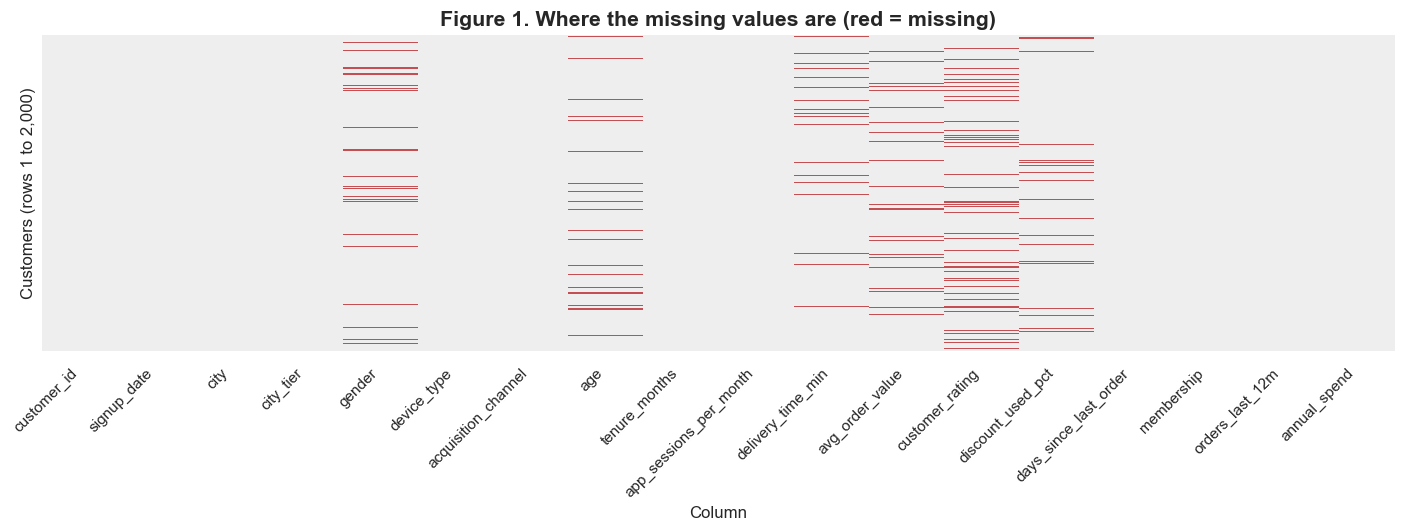

In [9]:
# Figure 1: heatmap of df.isna(). Red marks are missing cells. 2,000 rows share the chart height, so close rows merge.
fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(df.isna().astype(int), cmap=ListedColormap(["#EEEEEE", RED]), cbar=False, yticklabels=False, ax=ax)
ax.set_title("Figure 1. Where the missing values are (red = missing)", fontsize=14, fontweight="bold")
ax.set_xlabel("Column")
ax.set_ylabel("Customers (rows 1 to 2,000)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Findings from the first look

- The file has 2,000 rows and 18 columns. Customer IDs are unique and no row is duplicated.
- Six columns have gaps: `customer_rating` (258 missing, 12.9%), `age` (139, 7.0%), `avg_order_value` (108, 5.4%), `gender` (106, 5.3%), `discount_used_pct` (104, 5.2%) and `delivery_time_min` (80, 4.0%). That is 795 missing cells, about 2.2% of the table, but they are spread across roughly a third of the rows, so dropping incomplete rows would throw away far too much.
- In the heatmap the red marks are scattered with no visible blocks, so no batch of customers is missing everything at once.
- `describe()` already shows values that cannot be right: a minimum age of 0 and a maximum of 150, a delivery time of 500 minutes when the 75th percentile is 40.5, and an average order value of 32,000 rupees when the 75th percentile is 458.
- `annual_spend` and `orders_last_12m` have means far above their medians (12,996 vs 7,142 rupees, and 34.9 vs 24 orders), which points to a long right tail.
- The categories match the data dictionary, with no stray spellings, and each city maps to exactly one tier.
- Ratings stay within 1 to 5, discounts within 0 to 100%, and nothing is negative. Age is the only column that fails a range check.
- `tenure_months` agrees with `signup_date` exactly. For all 2,000 rows it equals the days since signup divided by 30, measured to 31 October 2026, so that is the date the extract was pulled. The shortest tenure is 12.0 months (360 days), which means the file only contains customers who signed up at least that long before the extract. Everyone also placed at least 5 orders in the year and ordered within the last 125 days, although 87 customers have gone more than 60 days without an order. This is an extract of established customers with orders in the past year. Newer customers are absent, and customers who stopped ordering appear to be absent too, which matters when reading the signup chart in Task 4.
- `orders_last_12m` takes only 51 distinct values (5, 7, 10, 13, 17, 20 and so on), so it appears to be rounded or bucketed at source. Nearly half of all customers sit on 17, 20 or 24, and 14 customers sit exactly at the maximum of 400. Neither changes the analysis, but both are worth raising with the data team.

## Task 2: Outlier detection and treatment

This task comes before imputation. The three columns to examine are `age`, `delivery_time_min` and `avg_order_value`.

### 2.1 Box plots before treatment

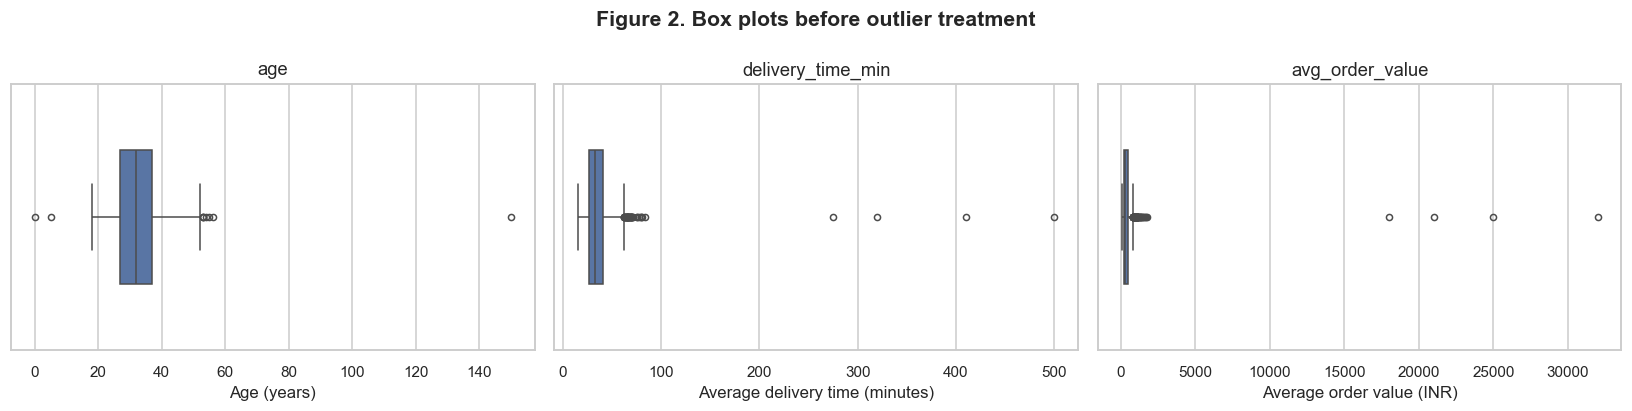

In [10]:
outlier_cols = ["age", "delivery_time_min", "avg_order_value"]
axis_labels = {
    "age": "Age (years)",
    "delivery_time_min": "Average delivery time (minutes)",
    "avg_order_value": "Average order value (INR)",
}

# Figure 2: one box plot per column, raw data
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, outlier_cols):
    sns.boxplot(x=df[col], color=BLUE, width=0.5, flierprops={"marker": "o", "markersize": 4}, ax=ax)
    ax.set_title(col)
    ax.set_xlabel(axis_labels[col])
fig.suptitle("Figure 2. Box plots before outlier treatment")
plt.tight_layout()
plt.show()

A handful of points sit so far out that the boxes are squashed flat, most obviously for delivery time and order value.

### 2.2 IQR rule vs Z-score rule

- IQR rule: a value is an outlier if it is below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR.
- Z-score rule: a value is an outlier if it is more than 3 standard deviations from the mean, |z| > 3.

In [11]:
# Helper functions for the two outlier rules. Both ignore missing values.

def iqr_bounds(s, k=1.5):
    """Return the lower and upper IQR fences of a Series."""
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


def iqr_outliers(s, k=1.5):
    """Boolean mask: True where the value falls outside the IQR fences."""
    low, high = iqr_bounds(s, k)
    return (s < low) | (s > high)


def z_scores(s):
    """Z-score of every value: distance from the mean in standard deviations."""
    return (s - s.mean()) / s.std()


def z_outliers(s, threshold=3):
    """Boolean mask: True where |z| is above the threshold."""
    return z_scores(s).abs() > threshold


def outlier_report(data, columns):
    """Compare the two rules side by side for a list of columns."""
    rows = []
    for col in columns:
        s = data[col].dropna()
        low, high = iqr_bounds(s)
        rows.append({
            "column": col,
            "mean": s.mean(),
            "std": s.std(),
            "IQR lower fence": low,
            "IQR upper fence": high,
            "outliers by IQR": int(iqr_outliers(s).sum()),
            "outliers by Z-score": int(z_outliers(s).sum()),
        })
    return pd.DataFrame(rows).set_index("column")


report_before = outlier_report(df, outlier_cols + ["orders_last_12m", "annual_spend"])
report_before

,mean,std,IQR lower fence,IQR upper fence,outliers by IQR,outliers by Z-score
column,,,,,,
age,31.93,7.62,12.00,52.00,9,5
delivery_time_min,34.99,19.49,4.75,61.95,46,4
avg_order_value,417.58,"1,133.67",-149.88,823.12,96,4
orders_last_12m,34.90,49.27,-5.50,54.50,231,41
annual_spend,"12,995.85","30,336.38","-8,957.50","25,824.50",165,21


In [12]:
# Look at the actual rows behind the most extreme values before deciding anything.
show_cols = ["customer_id", "city", "age", "delivery_time_min", "avg_order_value",
             "customer_rating", "membership", "orders_last_12m", "annual_spend"]

print("Ages outside 18 to 100:")
display(df.loc[(df["age"] < 18) | (df["age"] > 100), show_cols])

print("Delivery times above 120 minutes (next highest value is "
      f"{df.loc[df['delivery_time_min'] <= 120, 'delivery_time_min'].max()} minutes):")
display(df.loc[df["delivery_time_min"] > 120, show_cols])

# For the extreme baskets, compare with what the customer actually paid per order
suspect_aov = df.loc[df["avg_order_value"] > 5000, show_cols].copy()
suspect_aov["spend_per_order"] = suspect_aov["annual_spend"] / suspect_aov["orders_last_12m"]
print("Average order values above 5,000 INR (next highest value is "
      f"{df.loc[df['avg_order_value'] <= 5000, 'avg_order_value'].max():,.0f} INR):")
display(suspect_aov)

# For everyone else, does the recorded basket size agree with spend divided by orders?
normal_aov = df["avg_order_value"] <= 5000
spend_per_order = df["annual_spend"] / df["orders_last_12m"]
print("Correlation between avg_order_value and spend per order, all other customers: "
      f"{df.loc[normal_aov, 'avg_order_value'].corr(spend_per_order[normal_aov]):.2f}")
ratio = (spend_per_order / df["avg_order_value"])[normal_aov]
print(f"Spend per order divided by recorded basket size, all other customers: {ratio.min():.2f} to {ratio.max():.2f}")

# Apply the same check to the largest spender, whose basket size is missing
top_id = df["annual_spend"].idxmax()
print("\nLargest spender:")
display(df.loc[[top_id], show_cols].assign(spend_per_order=spend_per_order[top_id]))

Ages outside 18 to 100:


,customer_id,city,age,delivery_time_min,avg_order_value,customer_rating,membership,orders_last_12m,annual_spend
245,QB100245,Indore,5.00,NaN,569.00,4.60,Basic,17,"8,410.00"
1617,QB101617,Hyderabad,150.00,35.90,305.00,3.10,Basic,24,"5,952.00"
1792,QB101792,Delhi,0.00,28.00,239.00,2.70,Silver,20,"4,528.00"


Delivery times above 120 minutes (next highest value is 83.9 minutes):


,customer_id,city,age,delivery_time_min,avg_order_value,customer_rating,membership,orders_last_12m,annual_spend
1210,QB101210,Jaipur,33.00,410.00,294.00,4.80,Basic,17,"4,605.00"
1223,QB101223,Pune,37.00,275.00,178.00,4.50,Basic,20,"3,020.00"
1293,QB101293,Bengaluru,33.00,320.00,169.00,4.80,Basic,24,"3,616.00"
1417,QB101417,Hyderabad,43.00,500.00,273.00,5.00,Platinum,20,"7,390.00"


Average order values above 5,000 INR (next highest value is 1,729 INR):


,customer_id,city,age,delivery_time_min,avg_order_value,customer_rating,membership,orders_last_12m,annual_spend,spend_per_order
156,QB100156,Delhi,18.00,38.10,"18,000.00",NaN,Basic,17,"4,964.00",292.00
567,QB100567,Mumbai,23.00,29.80,"32,000.00",4.90,Gold,17,"5,061.00",297.71
693,QB100693,Bengaluru,33.00,27.50,"25,000.00",4.20,Basic,17,"7,519.00",442.29
1782,QB101782,Delhi,29.00,33.40,"21,000.00",NaN,Basic,7,826.00,118.00


Correlation between avg_order_value and spend per order, all other customers: 0.97
Spend per order divided by recorded basket size, all other customers: 0.72 to 1.45

Largest spender:


,customer_id,city,age,delivery_time_min,avg_order_value,customer_rating,membership,orders_last_12m,annual_spend,spend_per_order
236,QB100236,Hyderabad,36.00,29.80,NaN,4.60,Basic,400,"855,443.00","2,138.61"


### 2.3 What the two rules say

- The IQR rule flags many more points than the Z-score rule: 9 vs 5 for age, 46 vs 4 for delivery time and 96 vs 4 for order value.
- The Z-score rule is blunt here because the outliers inflate the standard deviation they are measured against. The four huge baskets push the standard deviation of `avg_order_value` to about 1,134 rupees, more than three times the median basket. Against that yardstick only those four values look unusual. This is called masking.
- The IQR rule has the opposite weakness on skewed data. The upper fence for order value is about 823 rupees, so it flags 96 customers, and 92 of them just have large but believable baskets, up to 1,729 rupees. A fence built for symmetric data will always cut into a long right tail.
- Neither rule can make the decision. They produce a list of candidates, and each candidate still needs a judgement about whether it is an error or a real customer.

### 2.4 Decision for each column

| Column | What was found | Decision | Why |
|---|---|---|---|
| `age` | Three impossible values: 0, 5 and 150. Every other customer is between 18 and 56. | Remove the value (set to missing) and impute it in Task 1. Keep the row. | These are data-entry errors, and nothing in the file says what the true age was. The rest of the row is usable. The ages of 53 to 56 that the IQR rule flags are real customers, so they stay. |
| `delivery_time_min` | Four values of 275 to 500 minutes. The next highest value is 83.9, so there is a wide gap. | Cap (winsorise) at 83.9, the largest ordinary value, and mark the rows in a new `delivery_extreme` column. | An average of four and a half to more than eight hours could be a real service failure or a logging fault. All four customers gave ratings of 4.5 or higher and ordered again within the last month. That hints at a logging fault, but only weakly, because ratings in this file barely move with delivery time. No other column contradicts these numbers the way spend contradicts the order values below, so they are treated as suspect and not as proven errors. Capping is the middle course: the rows stay in the slow tail where a real failure belongs, the flag keeps them findable for the operations team, and four rows no longer dominate every mean and correlation. If they turn out to be logging faults, the cost is four customers (0.2% of the base) counted as slow. The 42 other IQR flags (62 to 84 minutes) are slow but believable, so they stay as they are. |
| `avg_order_value` | Four values of 18,000 to 32,000 rupees. The next highest is 1,729. | Remove the value and impute it in Task 1. Keep the row. | For every other customer the recorded basket size and spend per order agree closely (correlation 0.97). For these four, spend per order is 118 to 442 rupees, so the recorded basket sizes contradict the spend data. They are data-entry errors. Capping would be wrong here: the spend data shows these customers have ordinary baskets, and a cap would still hand them the biggest basket in the company. The other IQR flags form the natural tail of a skewed variable and stay. |
| `orders_last_12m`, `annual_spend` | Hundreds of IQR flags and a very long right tail. | Keep everything. | These are the heavy users the leadership team is asking about. Removing them would delete the main finding of the project. One account needs a note. The largest spender (855,443 rupees over 400 orders) works out at 2,139 rupees per order, above the largest basket recorded for anyone (1,729), and their own basket size is missing. For other customers spend per order runs from 0.72 to 1.45 times the recorded basket, so 2,139 would need a basket of about 1,475 rupees or more. Only 5 of the 1,888 customers with a recorded basket have one that large. The figure is possible, but it would make this the most extreme account in the file. The row is kept, the amount should be confirmed with finance, and Task 7 shows the results with and without it. |

The facilitator notes mention four planted impossible ages. Only three are present in this file (0, 5 and 150).

In [13]:
# Keep a snapshot so the "before" box plots and tables can still be produced
df_before_outliers = df.copy()

# --- age: impossible values become missing -------------------------------------
bad_age = (df["age"] < 18) | (df["age"] > 100)
df.loc[bad_age, "age"] = np.nan

# --- delivery_time_min: flag the extreme cases, then cap them ------------------
extreme_delivery = df["delivery_time_min"] > 120
df["delivery_extreme"] = extreme_delivery                      # audit flag for the ops team
delivery_cap = df.loc[~extreme_delivery, "delivery_time_min"].max()
df.loc[extreme_delivery, "delivery_time_min"] = delivery_cap

# --- avg_order_value: erroneous basket sizes become missing ------------------------
bad_aov = df["avg_order_value"] > 5000
df.loc[bad_aov, "avg_order_value"] = np.nan

print(f"Ages set to missing            : {bad_age.sum()}")
print(f"Delivery times capped at {delivery_cap} : {extreme_delivery.sum()}")
print(f"Order values set to missing    : {bad_aov.sum()}")

Ages set to missing            : 3
Delivery times capped at 83.9 : 4
Order values set to missing    : 4


### 2.5 Box plots after treatment

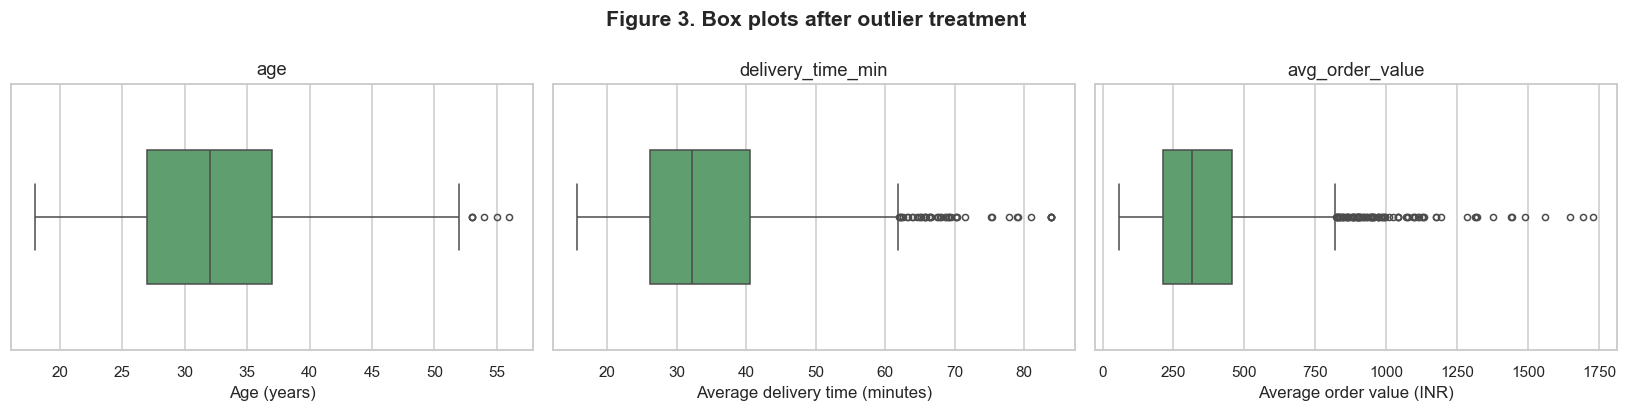

,mean before,mean after,std before,std after,skew before,skew after,max before,max after
age,31.93,31.89,7.62,7.05,2.03,0.13,150.00,56.00
delivery_time_min,34.99,34.38,19.49,11.23,13.55,1.06,500.00,83.90
avg_order_value,417.58,367.61,"1,133.67",219.73,21.99,1.75,"32,000.00","1,729.00"


Outlier counts after treatment:


,IQR lower fence,IQR upper fence,outliers by IQR,outliers by Z-score
column,,,,
age,12.00,52.00,6,3
delivery_time_min,4.75,61.95,46,21
avg_order_value,-148.62,820.38,93,29


In [14]:
# Figure 3: the same three box plots after treatment
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, outlier_cols):
    sns.boxplot(x=df[col], color=GREEN, width=0.5, flierprops={"marker": "o", "markersize": 4}, ax=ax)
    ax.set_title(col)
    ax.set_xlabel(axis_labels[col])
fig.suptitle("Figure 3. Box plots after outlier treatment")
plt.tight_layout()
plt.show()

# Effect of the treatment on the summary statistics
effect = pd.DataFrame({
    "mean before": df_before_outliers[outlier_cols].mean(),
    "mean after": df[outlier_cols].mean(),
    "std before": df_before_outliers[outlier_cols].std(),
    "std after": df[outlier_cols].std(),
    "skew before": df_before_outliers[outlier_cols].skew(),
    "skew after": df[outlier_cols].skew(),
    "max before": df_before_outliers[outlier_cols].max(),
    "max after": df[outlier_cols].max(),
})
display(effect)

# Re-run both rules on the treated data to see the masking effect disappear
print("Outlier counts after treatment:")
display(outlier_report(df, outlier_cols)[["IQR lower fence", "IQR upper fence", "outliers by IQR", "outliers by Z-score"]])

### Findings from outlier treatment

- Eleven values were treated out of 2,000 rows: three ages and four order values were blanked for imputation, and four delivery times were capped and flagged. No rows were deleted.
- The boxes are readable now. Delivery time and order value still show points beyond the upper whisker, which is expected for right-skewed variables and is real customer behaviour.
- The treatment changed the statistics a great deal for so few rows. The standard deviation of `avg_order_value` fell from about 1,134 to about 220, and its skewness from 22.0 to 1.75. Delivery time skewness fell from 13.6 to 1.06, and age skewness from 2.03 to 0.13.
- With the extreme values gone, the Z-score rule starts flagging the ordinary tail (29 order values and 21 delivery times, where before it found 4 of each). That confirms the earlier point: the four bad values were hiding everything else.

## Task 1: Missing value imputation

### 1.1 Missing values after outlier treatment

Blanking the three bad ages and four bad order values added seven missing cells to the original count.

In [15]:
# Snapshot before imputation: used for before/after comparisons and for Task 3
df_pre_impute = df.copy()

missing_before = pd.DataFrame({
    "missing in raw file": df_raw.isna().sum(),
    "missing after outlier step": df.drop(columns="delivery_extreme").isna().sum(),
})
missing_before = missing_before[missing_before["missing after outlier step"] > 0]
missing_before["% of rows"] = missing_before["missing after outlier step"] / len(df) * 100
missing_before

,missing in raw file,missing after outlier step,% of rows
gender,106,106,5.30
age,139,142,7.10
delivery_time_min,80,80,4.00
avg_order_value,108,112,5.60
customer_rating,258,258,12.90
discount_used_pct,104,104,5.20


### 1.2 Why is `customer_rating` missing so often?

Ratings are the column with the most gaps. If the gaps were random, customers with and without a rating would have similar delivery times. The next cell checks that.

,count,mean,median
rating present,1669,33.31,30.80
rating missing,251,41.51,40.00


,customers,pct_missing,avg_rating_given
delivery_time_min,,,
up to 25,394,4.31,4.29
25 to 35,754,4.51,4.30
35 to 45,456,26.32,4.29
over 45,316,25.32,4.22


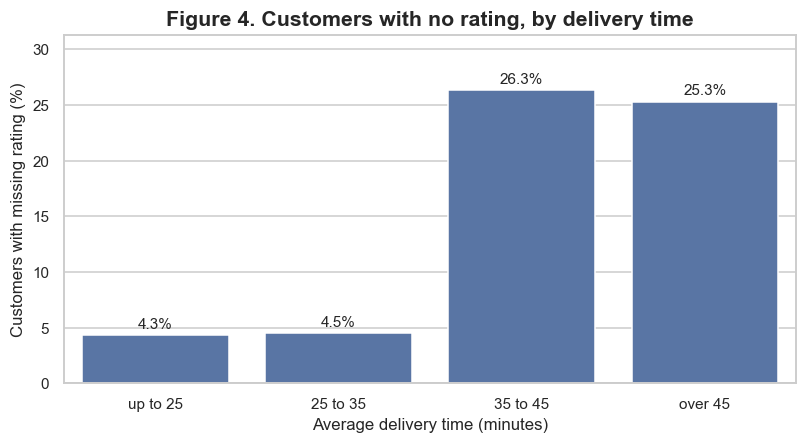

In [16]:
# Average delivery time for customers who did and did not leave a rating
rating_is_missing = df["customer_rating"].isna()
compare = df.groupby(rating_is_missing)["delivery_time_min"].agg(["count", "mean", "median"])
compare.index = ["rating present", "rating missing"]
display(compare)

# Share of customers with no rating, by delivery time band
bands = pd.cut(df["delivery_time_min"], bins=[0, 25, 35, 45, 90],
               labels=["up to 25", "25 to 35", "35 to 45", "over 45"])
by_band = df.groupby(bands, observed=True)["customer_rating"].agg(
    customers="size",
    pct_missing=lambda s: s.isna().mean() * 100,
    avg_rating_given="mean",
)
display(by_band)

# Figure 4: missing rating rate by delivery time band
fig, ax = plt.subplots(figsize=(7.5, 4.2))
sns.barplot(x=by_band.index.astype(str), y=by_band["pct_missing"], color=BLUE, ax=ax)
for i, v in enumerate(by_band["pct_missing"]):
    ax.text(i, v + 0.6, f"{v:.1f}%", ha="center", fontsize=10)
ax.set_title("Figure 4. Customers with no rating, by delivery time", fontsize=14, fontweight="bold")
ax.set_xlabel("Average delivery time (minutes)")
ax.set_ylabel("Customers with missing rating (%)")
ax.set_ylim(0, by_band["pct_missing"].max() + 5)
plt.tight_layout()
plt.show()

The gaps are not random. About 4% of customers with deliveries under 35 minutes have no rating, and the share jumps to about 26% once the average delivery time passes 35 minutes and stays near that level for longer waits. In the usual terms, the ratings are not missing completely at random: whether a rating is missing depends on another column. Customers without a rating wait about 42 minutes on average, against 33 for those who rated.

One reading is that customers who wait longer are less satisfied and skip the rating. The data cannot confirm that. The ratings that were given hardly change with delivery time (4.2 to 4.3 in every band), so there is no way to estimate what the silent customers would have said. What is certain is that the ratings on file under-represent customers with slower deliveries. Any fill value is a guess, and the median of 4.4 may flatter them. To keep that visible, a `rating_missing` flag is stored alongside the imputed value.

### 1.3 Impute each column

In [17]:
impute_log = {}   # column -> (method, value used) for the summary table

# Flag first, so the information "this customer never rated" survives imputation
df["rating_missing"] = df["customer_rating"].isna()

# --- age: median ---------------------------------------------------------------
age_mean, age_median = df["age"].mean(), df["age"].median()
print(f"age                -> mean {age_mean:.2f}, median {age_median:.1f} (raw mean with bad values: {df_raw['age'].mean():.2f})")
df["age"] = df["age"].fillna(age_median)
impute_log["age"] = ("median", age_median)

# --- delivery_time_min: median (right-skewed) ----------------------------------
del_mean, del_median = df["delivery_time_min"].mean(), df["delivery_time_min"].median()
print(f"delivery_time_min  -> mean {del_mean:.2f}, median {del_median:.2f}")
df["delivery_time_min"] = df["delivery_time_min"].fillna(del_median)
impute_log["delivery_time_min"] = ("median", del_median)

# --- avg_order_value: median within each city tier -----------------------------
aov_global_median = df["avg_order_value"].median()
aov_tier_median = df.groupby("city_tier")["avg_order_value"].median()
print(f"avg_order_value    -> global median {aov_global_median:.1f}; by tier: {aov_tier_median.to_dict()}")
df["avg_order_value"] = df["avg_order_value"].fillna(df["city_tier"].map(aov_tier_median))
impute_log["avg_order_value"] = ("median by city_tier", " / ".join(f"{v:g}" for v in aov_tier_median))

# --- customer_rating: median (left-skewed), compared with tier medians ---------
rating_mean, rating_median = df["customer_rating"].mean(), df["customer_rating"].median()
rating_tier_median = df.groupby("city_tier")["customer_rating"].median()
print(f"customer_rating    -> mean {rating_mean:.2f}, median {rating_median:.1f}; by tier: {rating_tier_median.to_dict()}")
df["customer_rating"] = df["customer_rating"].fillna(rating_median)
impute_log["customer_rating"] = ("median", rating_median)

# --- discount_used_pct: mean and median compared -------------------------------
disc_mean, disc_median = df["discount_used_pct"].mean(), df["discount_used_pct"].median()
print(f"discount_used_pct  -> mean {disc_mean:.2f}, median {disc_median:.2f}, skew {df['discount_used_pct'].skew():.2f}")
df["discount_used_pct"] = df["discount_used_pct"].fillna(disc_median)
impute_log["discount_used_pct"] = ("median", disc_median)

# --- gender: a new "Unknown" category instead of the mode ----------------------
print(f"gender             -> mode is '{df['gender'].mode()[0]}', {df['gender'].isna().sum()} missing become 'Unknown'")
df["gender"] = df["gender"].fillna("Unknown")

print("\nMissing values left in the dataset:", int(df.isna().sum().sum()))

age                -> mean 31.89, median 32.0 (raw mean with bad values: 31.93)
delivery_time_min  -> mean 34.38, median 32.25
avg_order_value    -> global median 315.0; by tier: {1: 325.0, 2: 309.0, 3: 289.5}
customer_rating    -> mean 4.29, median 4.4; by tier: {1: 4.4, 2: 4.5, 3: 4.4}
discount_used_pct  -> mean 22.50, median 22.40, skew 0.13
gender             -> mode is 'Male', 106 missing become 'Unknown'

Missing values left in the dataset: 0


### 1.4 Before-and-after table

In [18]:
# Numeric columns: missing counts and summary statistics before vs after imputation
rows = []
for col, (method, value) in impute_log.items():
    before, after = df_pre_impute[col], df[col]
    rows.append({
        "column": col,
        "method": method,
        "fill value": value,
        "missing before": int(before.isna().sum()),
        "missing after": int(after.isna().sum()),
        "mean before": before.mean(),
        "mean after": after.mean(),
        "median before": before.median(),
        "median after": after.median(),
        "std before": before.std(),
        "std after": after.std(),
    })
before_after = pd.DataFrame(rows).set_index("column")
display(before_after)

# Gender: category counts before vs after
gender_table = pd.DataFrame({
    "before": df_pre_impute["gender"].value_counts(dropna=False),
    "after": df["gender"].value_counts(),
}).fillna(0).astype(int)
gender_table.index = gender_table.index.fillna("(missing)")
display(gender_table)

,method,fill value,missing before,missing after,mean before,mean after,median before,median after,std before,std after
column,,,,,,,,,,
age,median,32.00,142,0,31.89,31.90,32.00,32.00,7.05,6.79
delivery_time_min,median,32.25,80,0,34.38,34.30,32.25,32.25,11.23,11.01
avg_order_value,median by city_tier,325 / 309 / 289.5,112,0,367.61,364.61,315.00,316.00,219.73,213.87
customer_rating,median,4.40,258,0,4.29,4.30,4.40,4.40,0.61,0.57
discount_used_pct,median,22.40,104,0,22.50,22.49,22.40,22.40,9.48,9.23


,before,after
gender,,
Female,836,836
Male,1023,1023
Other,35,35
Unknown,0,106
(missing),106,0


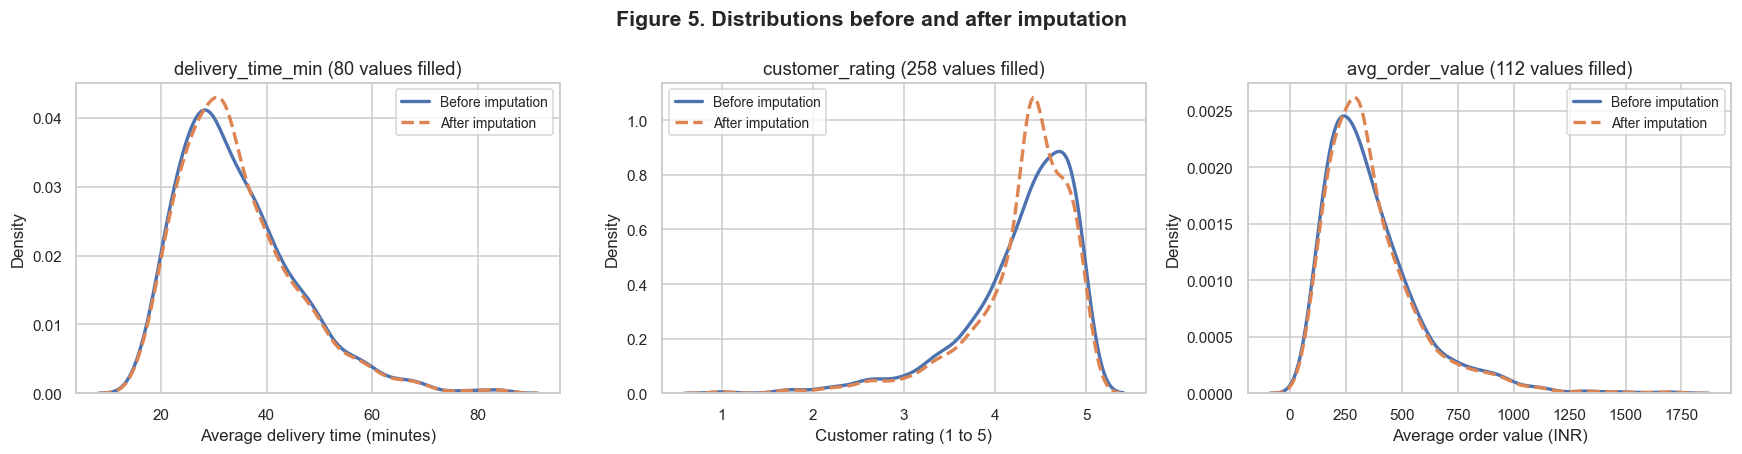

In [19]:
# Figure 5: KDE of the observed values (before) against the imputed column (after)
kde_cols = ["delivery_time_min", "customer_rating", "avg_order_value"]
kde_labels = {"delivery_time_min": "Average delivery time (minutes)",
              "customer_rating": "Customer rating (1 to 5)",
              "avg_order_value": "Average order value (INR)"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, col in zip(axes, kde_cols):
    sns.kdeplot(df_pre_impute[col].dropna(), color=BLUE, lw=2.2, label="Before imputation", ax=ax)
    sns.kdeplot(df[col], color=ORANGE, lw=2.2, ls="--", label="After imputation", ax=ax)
    n_filled = int(df_pre_impute[col].isna().sum())
    ax.set_title(f"{col} ({n_filled} values filled)")
    ax.set_xlabel(kde_labels[col])
    ax.set_ylabel("Density")
    ax.legend()
fig.suptitle("Figure 5. Distributions before and after imputation")
plt.tight_layout()
plt.show()

### Findings and reflections on imputation

**age: why the median and not the mean?** The median does not move when a few values are extreme or wrong. With the three bad ages still in, the mean was 31.93. After removing them the mean and median are both close to 32, so here either would do. The median is the safer habit because it would have given the right answer even if the bad values had been missed.

**delivery_time_min: what would the mean do?** Delivery time is right-skewed, so the mean (34.4 minutes after capping) sits above the median (32.25). Filling with the mean would give 80 customers a delivery time slower than what a typical customer gets. Before the four extreme values were capped the mean was 35.0, which would have been worse still. Delivery time differs by city tier more than order value does (medians of 30.2, 33.25 and 37.1 minutes), so a tier-wise fill would be at least as easy to justify here. The global median follows the brief and touches only 80 customers, and Task 8 works from observed values so that its probabilities do not depend on this choice.

**avg_order_value: group-wise or global?** Baskets get smaller as the tier number goes up: the median is 325 rupees in tier 1, 309 in tier 2 and 289.5 in tier 3, against 315 overall. Filling by tier keeps that difference. A single global value would nudge tier 3 customers up and tier 1 customers down. The gap is modest, so the practical effect is small, but the group-wise fill costs nothing extra. A sharper option exists in this data: spend per order tracks the recorded basket closely (correlation 0.97) and could give each customer their own estimate. It is not used here because it would build the basket size out of `annual_spend`, the variable the rest of the analysis is trying to explain. The cost of the simpler fill shows up in one row: the largest spender has no recorded basket and receives the tier median of 325 rupees, although their spend per order is 2,139. Task 4 shows what that does to the correlation.

**customer_rating: is missingness related to delivery time?** Yes, as section 1.2 showed. The global median (4.4) is used because the tier medians are almost identical (4.4, 4.5, 4.4), so grouping adds nothing. Ratings are left-skewed, which puts the mean (4.29) below the median. This fill may be optimistic for customers who waited longest, which is why the `rating_missing` flag is kept.

**discount_used_pct: mean or median?** The distribution is nearly symmetric (skew 0.13), so the mean (22.50) and the median (22.40) are the same for practical purposes. The median was used for consistency with the other columns.

**gender: mode or "Unknown"?** "Unknown" is the more honest choice. Filling with the mode would turn 106 customers into men with no evidence, and it would push the male share from 51% to 56%. A separate category keeps the fact that the value was never recorded.

**Did imputation distort the distributions?** Figure 5 shows the before and after curves almost on top of each other for delivery time and order value. The rating curve has a visibly taller peak at 4.4, because 258 values (12.9% of the column) were all placed on one point. That is the cost of single-value imputation: the centre is preserved but the spread shrinks a little. The table shows the same thing, with medians unchanged (the order value median moves from 315 to 316) and standard deviations slightly lower.

## Task 3: Distribution shapes with KDE plots

Each plot below is a histogram with a KDE curve, with vertical lines for the mean, median and mode.

Two choices about method:

- The shapes are drawn from the observed values only (after outlier treatment, before imputation). Imputed values all sit on the median, so including them would create an artificial spike and a fake mode.
- For continuous variables the most frequent exact value is not a useful mode. The mode shown here is the peak of the KDE curve, which is where values are densest.

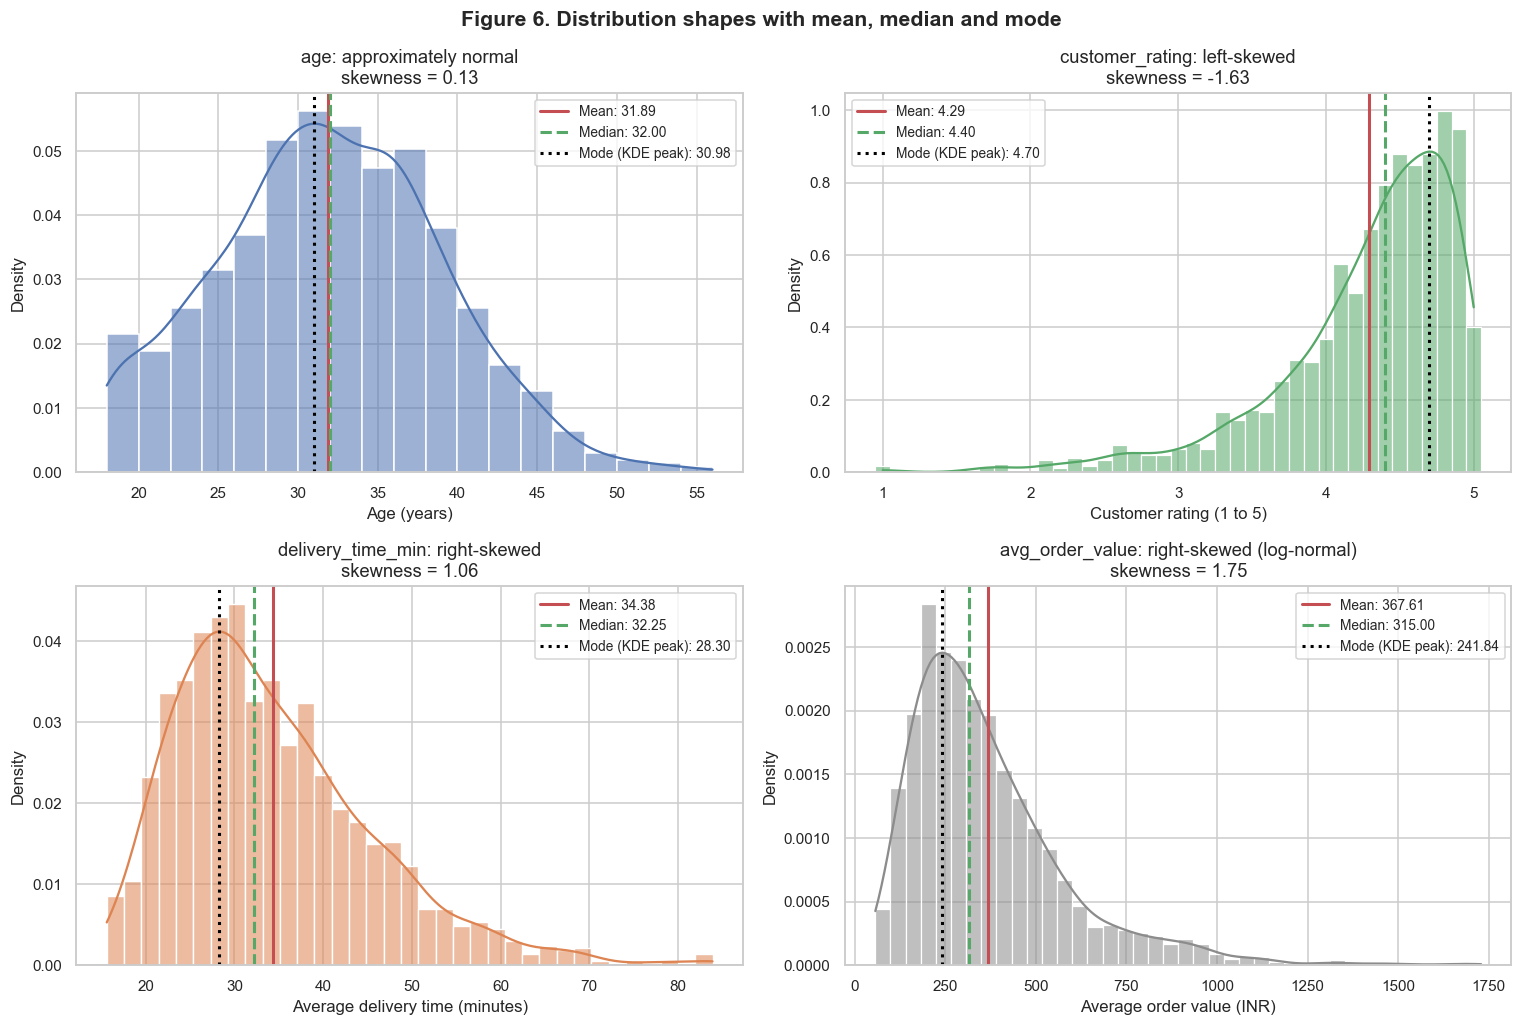

In [20]:
def plot_shape(ax, s, title, xlabel, color=BLUE, **hist_kwargs):
    """Histogram + KDE with mean, median and mode (KDE peak) marked. Returns the statistics."""
    s = s.dropna()
    sns.histplot(s, kde=True, stat="density", color=color, edgecolor="white", alpha=0.55, ax=ax, **hist_kwargs)

    # The KDE curve is the first line on the axis: its highest point is the mode
    kde_x, kde_y = ax.lines[0].get_data()
    mode = kde_x[np.argmax(kde_y)]
    mean, median, skew = s.mean(), s.median(), s.skew()

    ax.axvline(mean, color=RED, lw=2, ls="-", label=f"Mean: {mean:,.2f}")
    ax.axvline(median, color=GREEN, lw=2, ls="--", label=f"Median: {median:,.2f}")
    ax.axvline(mode, color="black", lw=2, ls=":", label=f"Mode (KDE peak): {mode:,.2f}")
    ax.set_title(f"{title}\nskewness = {skew:.2f}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Density")
    ax.legend()
    return {"mean": mean, "median": median, "mode (KDE peak)": mode, "skewness": skew, "std": s.std()}


obs = df_pre_impute          # observed values only
shape_stats = {}

# Figure 6: the four main variables
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
shape_stats["age"] = plot_shape(axes[0, 0], obs["age"], "age: approximately normal", "Age (years)", binwidth=2)
shape_stats["customer_rating"] = plot_shape(axes[0, 1], obs["customer_rating"], "customer_rating: left-skewed",
                                            "Customer rating (1 to 5)", color=GREEN, bins=np.arange(0.95, 5.1, 0.1))
shape_stats["delivery_time_min"] = plot_shape(axes[1, 0], obs["delivery_time_min"], "delivery_time_min: right-skewed",
                                              "Average delivery time (minutes)", color=ORANGE, bins=35)
shape_stats["avg_order_value"] = plot_shape(axes[1, 1], obs["avg_order_value"], "avg_order_value: right-skewed (log-normal)",
                                            "Average order value (INR)", color=GREY, bins=40)
fig.suptitle("Figure 6. Distribution shapes with mean, median and mode")
plt.tight_layout()
plt.show()

### 3.1 Is `avg_order_value` log-normal?

A variable is log-normal if its logarithm is normally distributed. Taking `np.log` of the order values should turn the skewed curve into a roughly symmetric bell.

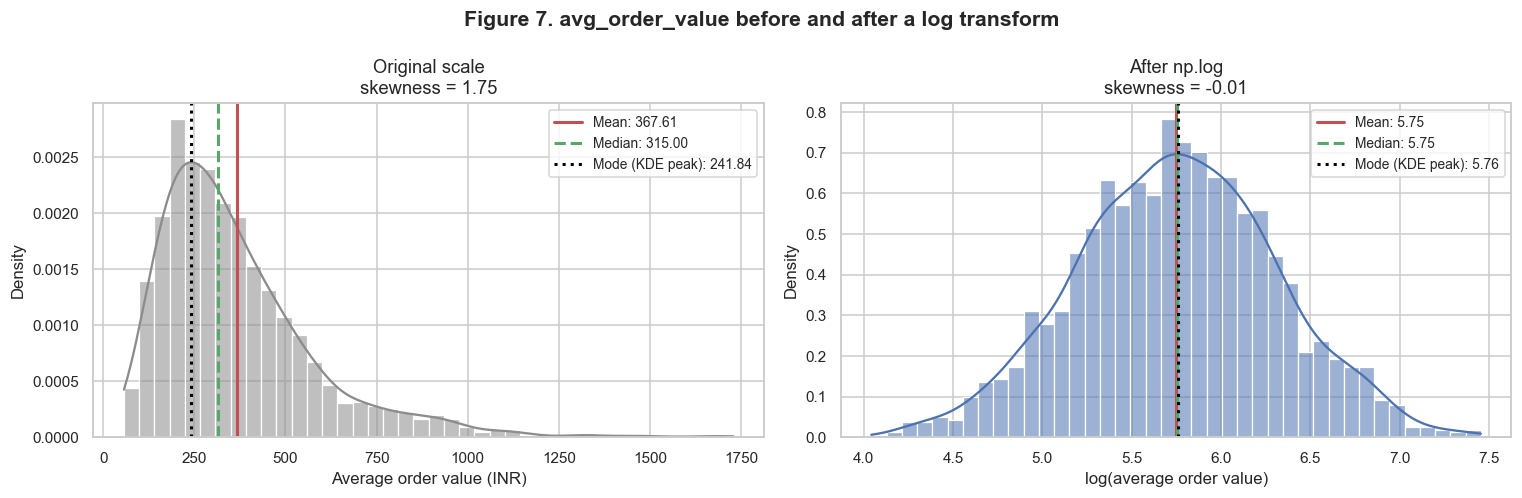

In [21]:
# Figure 7: average order value on the original scale and after a log transform
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
plot_shape(axes[0], obs["avg_order_value"], "Original scale", "Average order value (INR)", color=GREY, bins=40)
shape_stats["log(avg_order_value)"] = plot_shape(axes[1], np.log(obs["avg_order_value"]), "After np.log",
                                                 "log(average order value)", color=BLUE, bins=40)
fig.suptitle("Figure 7. avg_order_value before and after a log transform")
plt.tight_layout()
plt.show()

### 3.2 The heavy-tailed variables

`annual_spend` and `orders_last_12m` are shown here for shape only. Task 7 looks at them properly.

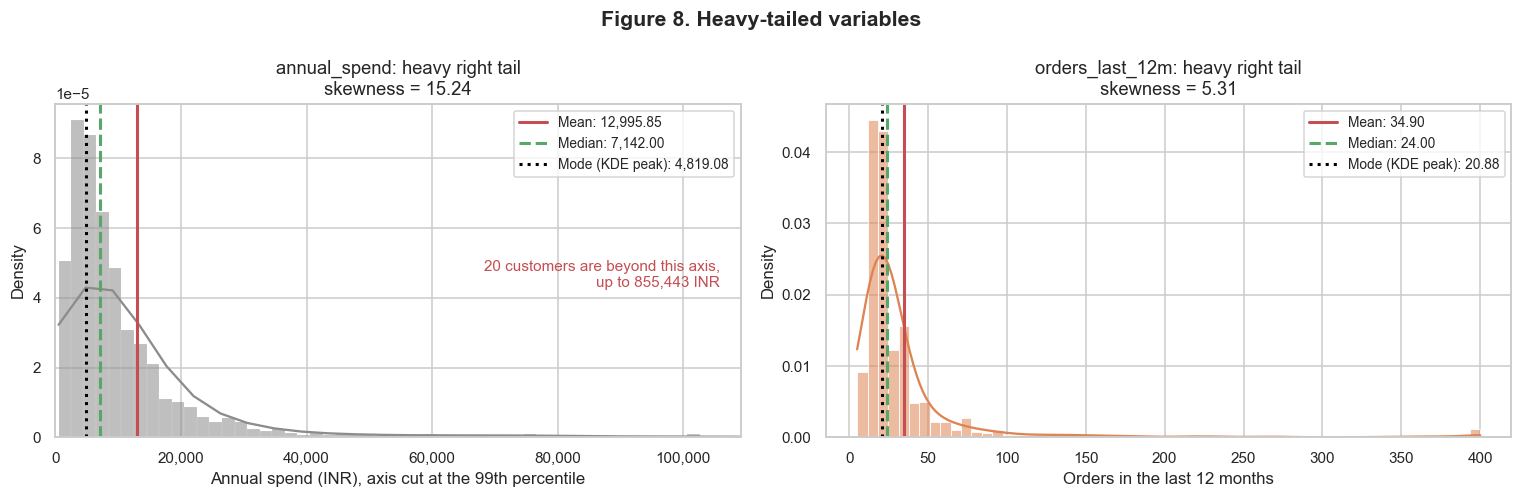

,mean,median,mode (KDE peak),skewness,order of centres
age,31.89,32.00,30.98,0.13,mean ≈ median ≈ mode
customer_rating,4.29,4.40,4.70,-1.63,mean < median < mode
delivery_time_min,34.38,32.25,28.30,1.06,mode < median < mean
avg_order_value,367.61,315.00,241.84,1.75,mode < median < mean
log(avg_order_value),5.75,5.75,5.76,-0.01,mean ≈ median ≈ mode
annual_spend,"12,995.85","7,142.00","4,819.08",15.24,mode < median < mean
orders_last_12m,34.90,24.00,20.88,5.31,mode < median < mean


In [22]:
# Figure 8: heavy right tails
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
shape_stats["annual_spend"] = plot_shape(axes[0], obs["annual_spend"], "annual_spend: heavy right tail",
                                         "Annual spend (INR), axis cut at the 99th percentile", color=GREY, binwidth=2000)
axes[0].xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

# The full axis would run to 855,443 and squash everything into one bar, so the view stops at P99.
# The statistics in the legend and title still use every customer.
spend_p99 = obs["annual_spend"].quantile(0.99)
n_beyond = int((obs["annual_spend"] > spend_p99).sum())
axes[0].set_xlim(0, spend_p99)
axes[0].text(0.97, 0.45, f"{n_beyond} customers are beyond this axis,\nup to {obs['annual_spend'].max():,.0f} INR",
             transform=axes[0].transAxes, ha="right", fontsize=10, color=RED)
shape_stats["orders_last_12m"] = plot_shape(axes[1], obs["orders_last_12m"], "orders_last_12m: heavy right tail",
                                            "Orders in the last 12 months", color=ORANGE, bins=60)
fig.suptitle("Figure 8. Heavy-tailed variables")
plt.tight_layout()
plt.show()

# Skewness and the three centres for every variable in this task
def centre_order(row):
    """Order of the three centres, read from the numbers themselves. If all three sit
    within 0.2 standard deviations of each other they are reported as roughly equal."""
    centres = {"mean": row["mean"], "median": row["median"], "mode": row["mode (KDE peak)"]}
    if max(centres.values()) - min(centres.values()) < 0.2 * row["std"]:
        return "mean ≈ median ≈ mode"
    return " < ".join(sorted(centres, key=centres.get))


shape_table = pd.DataFrame(shape_stats).T
shape_table["order of centres"] = shape_table.apply(centre_order, axis=1)
shape_table.drop(columns="std")

### Findings on distribution shapes

| Variable | Skewness | Shape |
|---|---|---|
| `age` | 0.13 | Approximately normal. Mean and median are both about 32 and the curve is close to symmetric. There is a small pile-up at 18, the youngest age in the file (53 customers, against 27 aged 19), which looks like a minimum age being applied. |
| `customer_rating` | −1.63 | Left-skewed. Most ratings are between 4 and 5, with a thin tail of unhappy customers down to 1. |
| `delivery_time_min` | 1.06 | Right-skewed. The middle half of customers average between about 26 and 40 minutes, and a tail runs out past 80. |
| `avg_order_value` | 1.75 | Right-skewed. After `np.log` the skewness is about −0.01 and the curve is a symmetric bell, so the variable is log-normal. |
| `annual_spend` | 15.24 | Very heavy right tail. Four in five customers spend under 15,000 rupees, while the top 1% run from about 109,000 up to 855,000, too far out to fit on the axis. |
| `orders_last_12m` | 5.31 | Heavy right tail, with a small bump at the 400-order ceiling. The values are bucketed, so the KDE peak near 21 falls between two real values. The most common actual value is 17. |

**Why the order of mean, median and mode flips.** The mode is the peak of the curve and does not care about the tails. The mean is the balance point, so every extreme value pulls it. The median only counts how many values are on each side, so it moves less than the mean.

- In a right-skewed variable the tail is on the high side. It drags the mean furthest, the median a little, and the mode not at all: mode < median < mean. Delivery time shows it, with a mode near 28 minutes, a median of 32.25 and a mean of 34.4.
- In a left-skewed variable the tail is on the low side, so the order reverses: mean < median < mode. Ratings have a mean of 4.29, a median of 4.4 and a peak near 4.7.
- In a symmetric variable such as age the three almost coincide.

For skewed variables the mean is not what a typical customer sees. For delivery time, order value and spend, the median describes a typical customer better.

## Task 4: Relationships between variables

From here on the analysis uses the cleaned and imputed dataset. Imputed values all sit at a median, which pulls correlations slightly towards zero. Where that changes a conclusion, the figure for observed values is shown next to it.

### 4.1 Covariance matrix

In [23]:
# Numeric columns used for covariance and correlation
num_cols = ["age", "city_tier", "tenure_months", "app_sessions_per_month", "delivery_time_min",
            "avg_order_value", "customer_rating", "discount_used_pct", "days_since_last_order",
            "orders_last_12m", "annual_spend"]

cov_matrix = df[num_cols].cov()
cov_matrix.round(1)

,age,city_tier,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend
age,46.20,0.10,1.10,-0.40,4.60,17.80,-0.00,-16.00,-1.90,2.90,"5,424.30"
city_tier,0.10,0.60,0.10,0.10,1.80,-20.10,-0.00,-0.20,0.40,0.90,-102.20
tenure_months,1.10,0.10,99.60,-0.20,-0.60,-28.00,0.10,-0.20,-3.00,-7.70,"-3,633.60"
app_sessions_per_month,-0.40,0.10,-0.20,14.30,-1.60,3.10,0.00,-0.90,1.90,14.00,"9,728.30"
delivery_time_min,4.60,1.80,-0.60,-1.60,121.10,-91.40,0.00,-0.90,-2.00,-5.50,"-3,022.80"
avg_order_value,17.80,-20.10,-28.00,3.10,-91.40,"45,739.60",0.90,-2.40,-145.80,215.10,"1,636,312.30"
customer_rating,-0.00,-0.00,0.10,0.00,0.00,0.90,0.30,-0.00,-0.70,-0.20,14.90
discount_used_pct,-16.00,-0.20,-0.20,-0.90,-0.90,-2.40,-0.00,85.30,-6.10,5.90,"-8,300.50"
days_since_last_order,-1.90,0.40,-3.00,1.90,-2.00,-145.80,-0.70,-6.10,360.40,8.80,"-9,480.90"
orders_last_12m,2.90,0.90,-7.70,14.00,-5.50,215.10,-0.20,5.90,8.80,"2,428.00","1,083,302.20"


### 4.2 Correlation matrix

In [24]:
# Pearson correlation: covariance divided by the two standard deviations, so it runs from -1 to +1
corr_matrix = df[num_cols].corr()
corr_matrix.round(2)

,age,city_tier,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend
age,1.00,0.01,0.02,-0.02,0.06,0.01,-0.00,-0.25,-0.01,0.01,0.03
city_tier,0.01,1.00,0.02,0.02,0.21,-0.12,-0.00,-0.02,0.03,0.02,-0.00
tenure_months,0.02,0.02,1.00,-0.01,-0.01,-0.01,0.02,-0.00,-0.02,-0.02,-0.01
app_sessions_per_month,-0.02,0.02,-0.01,1.00,-0.04,0.00,0.01,-0.03,0.03,0.08,0.08
delivery_time_min,0.06,0.21,-0.01,-0.04,1.00,-0.04,0.00,-0.01,-0.01,-0.01,-0.01
avg_order_value,0.01,-0.12,-0.01,0.00,-0.04,1.00,0.01,-0.00,-0.04,0.02,0.25
customer_rating,-0.00,-0.00,0.02,0.01,0.00,0.01,1.00,-0.00,-0.07,-0.01,0.00
discount_used_pct,-0.25,-0.02,-0.00,-0.03,-0.01,-0.00,-0.00,1.00,-0.03,0.01,-0.03
days_since_last_order,-0.01,0.03,-0.02,0.03,-0.01,-0.04,-0.07,-0.03,1.00,0.01,-0.02
orders_last_12m,0.01,0.02,-0.02,0.08,-0.01,0.02,-0.01,0.01,0.01,1.00,0.72


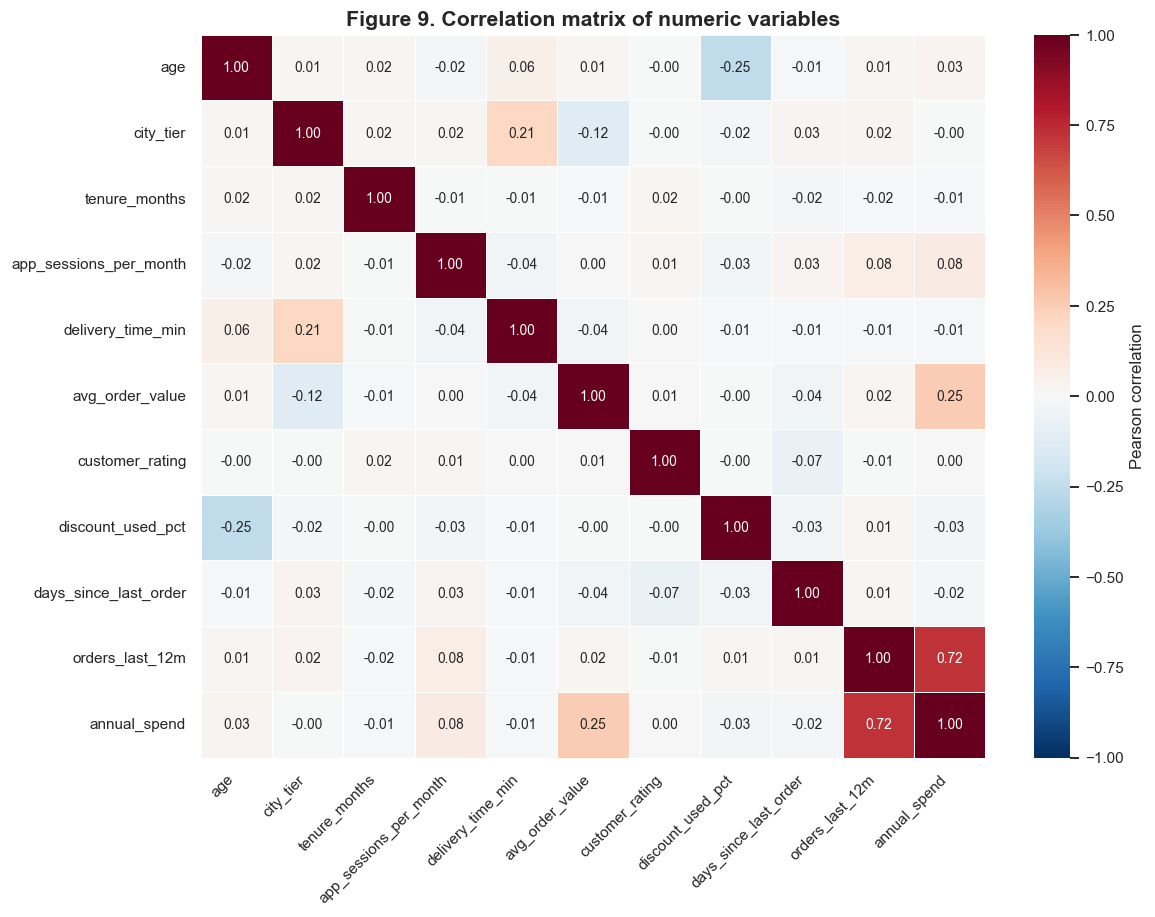

Correlation with annual_spend:
orders_last_12m           +0.725
avg_order_value           +0.252
app_sessions_per_month    +0.085
discount_used_pct         -0.030
age                       +0.026
days_since_last_order     -0.016
tenure_months             -0.012
delivery_time_min         -0.009
city_tier                 -0.004
customer_rating           +0.001


In [25]:
# Figure 9: annotated correlation heatmap
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=0.5, annot_kws={"size": 9}, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Figure 9. Correlation matrix of numeric variables", fontsize=14, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Correlation of every numeric variable with annual_spend, strongest first
spend_corr = corr_matrix["annual_spend"].drop("annual_spend").sort_values(key=abs, ascending=False)
print("Correlation with annual_spend:")
print(spend_corr.map("{:+.3f}".format).to_string())

**Why correlation is easier to read than covariance.** Covariance is in the units of the two variables multiplied together, so its size depends on the scales: the covariance of `orders_last_12m` and `annual_spend` is over a million simply because spend is measured in thousands of rupees. Correlation divides the covariance by both standard deviations, which gives a unit-free number between −1 and +1 that can be compared across any pair of variables.

### 4.3 Scatter plots

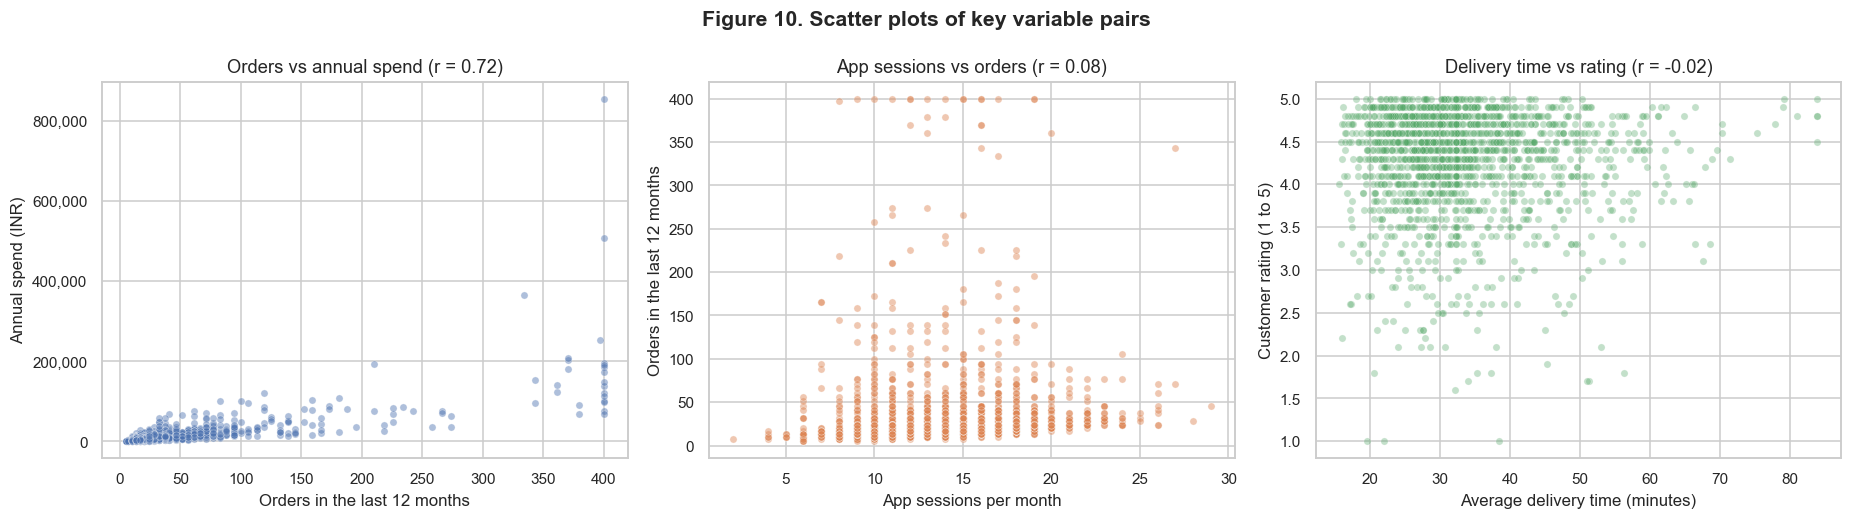

In [26]:
# Figure 10: three scatter plots
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# (a) orders vs annual spend
sns.scatterplot(data=df, x="orders_last_12m", y="annual_spend", alpha=0.45, s=22, color=BLUE, ax=axes[0])
axes[0].set_title(f"Orders vs annual spend (r = {df['orders_last_12m'].corr(df['annual_spend']):.2f})")
axes[0].set_xlabel("Orders in the last 12 months")
axes[0].set_ylabel("Annual spend (INR)")
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

# (b) app sessions vs orders
sns.scatterplot(data=df, x="app_sessions_per_month", y="orders_last_12m", alpha=0.45, s=22, color=ORANGE, ax=axes[1])
axes[1].set_title(f"App sessions vs orders (r = {df['app_sessions_per_month'].corr(df['orders_last_12m']):.2f})")
axes[1].set_xlabel("App sessions per month")
axes[1].set_ylabel("Orders in the last 12 months")

# (c) delivery time vs rating (only customers who actually gave a rating)
rated = df[~df["rating_missing"]]
sns.scatterplot(data=rated, x="delivery_time_min", y="customer_rating", alpha=0.35, s=22, color=GREEN, ax=axes[2])
axes[2].set_title(f"Delivery time vs rating (r = {rated['delivery_time_min'].corr(rated['customer_rating']):.2f})")
axes[2].set_xlabel("Average delivery time (minutes)")
axes[2].set_ylabel("Customer rating (1 to 5)")

fig.suptitle("Figure 10. Scatter plots of key variable pairs")
plt.tight_layout()
plt.show()

### 4.4 Line plots over signup month

Dropping November 2025: signup dates stop on 2025-11-05 (7 customers)


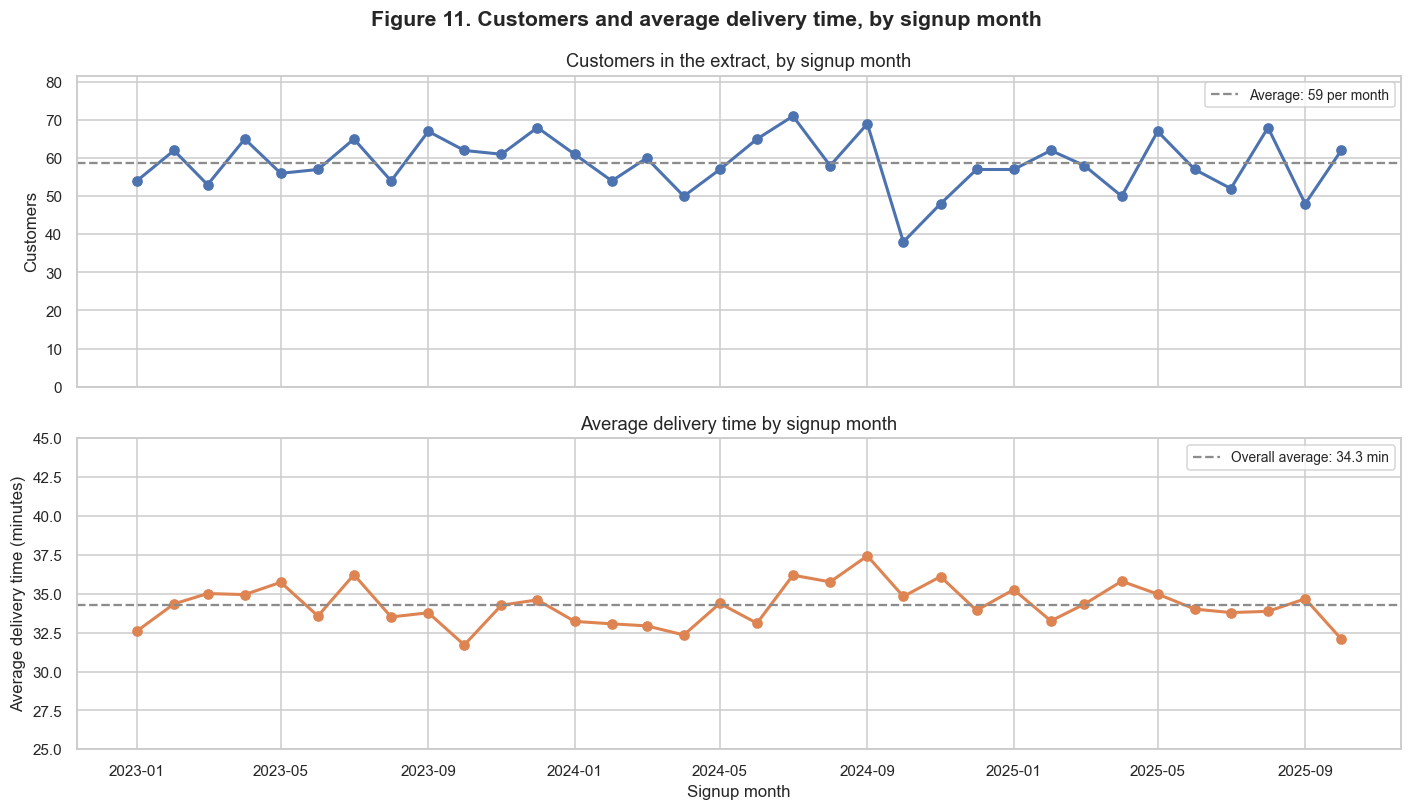

Signups per month: min 38, max 71, mean 58.6
Avg delivery by signup month: min 31.7, max 37.4
Signups by year: {2023: 724, 2024: 688, 2025: 581}


In [27]:
# Customers by signup month, and the average delivery time of the customers who signed up in each month
monthly = df.set_index("signup_date").resample("MS").agg(
    signups=("customer_id", "count"),
    avg_delivery=("delivery_time_min", "mean"),
)

# The last signup month is cut short by the 12-month tenure rule (section 0.4), so it is incomplete: leave it out
last_date = df["signup_date"].max()
if last_date < monthly.index[-1] + pd.offsets.MonthEnd(0):
    print(f"Dropping {monthly.index[-1]:%B %Y}: signup dates stop on {last_date.date()} "
          f"({int(monthly['signups'].iloc[-1])} customers)")
    monthly = monthly.iloc[:-1]

# Figure 11: two line plots sharing the time axis
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True)

axes[0].plot(monthly.index, monthly["signups"], marker="o", color=BLUE, lw=2)
axes[0].axhline(monthly["signups"].mean(), color=GREY, ls="--", label=f"Average: {monthly['signups'].mean():.0f} per month")
axes[0].set_title("Customers in the extract, by signup month")
axes[0].set_ylabel("Customers")
axes[0].set_ylim(0, monthly["signups"].max() * 1.15)
axes[0].legend()

axes[1].plot(monthly.index, monthly["avg_delivery"], marker="o", color=ORANGE, lw=2)
axes[1].axhline(df["delivery_time_min"].mean(), color=GREY, ls="--", label=f"Overall average: {df['delivery_time_min'].mean():.1f} min")
axes[1].set_title("Average delivery time by signup month")
axes[1].set_ylim(25, 45)       # a wider axis, so month-to-month noise is not read as a trend
axes[1].set_xlabel("Signup month")
axes[1].set_ylabel("Average delivery time (minutes)")
axes[1].legend()

fig.suptitle("Figure 11. Customers and average delivery time, by signup month")
plt.tight_layout()
plt.show()

print(f"Signups per month: min {monthly['signups'].min()}, max {monthly['signups'].max()}, mean {monthly['signups'].mean():.1f}")
print(f"Avg delivery by signup month: min {monthly['avg_delivery'].min():.1f}, max {monthly['avg_delivery'].max():.1f}")
print("Signups by year:", monthly["signups"].groupby(monthly.index.year).sum().to_dict())

### 4.5 Box plots by category

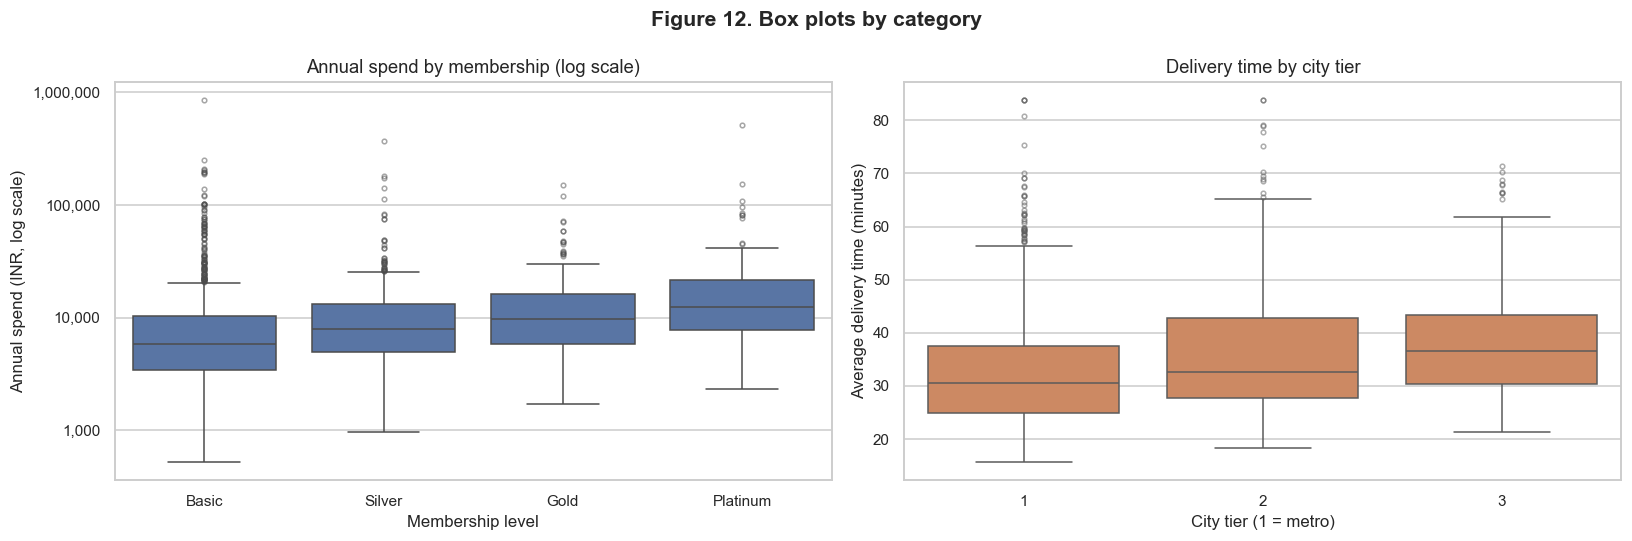

Annual spend by membership:


,count,median,mean
membership,,,
Basic,1179,"5,875.00","11,784.79"
Silver,436,"7,993.00","12,827.41"
Gold,237,"9,802.00","14,033.21"
Platinum,148,"12,362.50","21,478.47"


Delivery time by city tier:


,count,median,mean,% over 45 min
city_tier,,,,
1,1155,30.60,32.39,11.86
2,489,32.60,36.11,21.06
3,356,36.60,38.01,21.35


Median annual spend by gender, device and acquisition channel:


,customers,median_spend
gender,,
Unknown,106,"8,202.00"
Female,836,"7,174.00"
Male,1023,"7,008.00"
Other,35,"6,949.00"


,customers,median_spend
device_type,,
Web,174,"7,448.00"
Android,1171,"7,201.00"
iOS,655,"6,819.00"


,customers,median_spend
acquisition_channel,,
Paid Social,492,"7,598.00"
Referral,418,"7,439.50"
Organic,592,"7,057.50"
Search Ads,279,"6,785.00"
Influencer,219,"6,108.00"


In [28]:
membership_order = ["Basic", "Silver", "Gold", "Platinum"]

# Figure 12: spend by membership, delivery time by city tier
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=df, x="membership", y="annual_spend", order=membership_order, color=BLUE,
            flierprops={"marker": "o", "markersize": 3, "alpha": 0.5}, ax=axes[0])
axes[0].set_yscale("log")   # log scale, otherwise a few very large spenders flatten every box
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
axes[0].set_title("Annual spend by membership (log scale)")
axes[0].set_xlabel("Membership level")
axes[0].set_ylabel("Annual spend (INR, log scale)")

sns.boxplot(data=df, x="city_tier", y="delivery_time_min", color=ORANGE,
            flierprops={"marker": "o", "markersize": 3, "alpha": 0.5}, ax=axes[1])
axes[1].set_title("Delivery time by city tier")
axes[1].set_xlabel("City tier (1 = metro)")
axes[1].set_ylabel("Average delivery time (minutes)")

fig.suptitle("Figure 12. Box plots by category")
plt.tight_layout()
plt.show()

# The numbers behind the two charts
print("Annual spend by membership:")
display(df.groupby("membership")["annual_spend"].agg(["count", "median", "mean"]).reindex(membership_order))
print("Delivery time by city tier:")
tier_delivery = df.groupby("city_tier")["delivery_time_min"].agg(["count", "median", "mean"])
tier_delivery["% over 45 min"] = df.groupby("city_tier")["delivery_time_min"].apply(lambda s: (s > 45).mean() * 100)
display(tier_delivery)

# The unordered categories: does typical spend differ between groups?
print("Median annual spend by gender, device and acquisition channel:")
for col in ["gender", "device_type", "acquisition_channel"]:
    display(df.groupby(col)["annual_spend"].agg(customers="count", median_spend="median").sort_values("median_spend", ascending=False))

### 4.6 How far can these correlations be trusted?

Pearson correlation is sensitive to a few extreme points, and this dataset has a very long tail. Two checks follow. The first leaves out the largest account. The second repeats the calculation on log values, which stops a few very large accounts from deciding the result. The log version is shown for all customers and for those whose basket size was recorded and not imputed.

In [29]:
drivers = ["orders_last_12m", "avg_order_value", "app_sessions_per_month"]

top_id = df["annual_spend"].idxmax()                          # the largest spender
no_top = df.drop(index=top_id)
recorded = df[df_pre_impute["avg_order_value"].notna()]       # basket size recorded, not imputed
logs_all = np.log(df[drivers + ["annual_spend"]])             # log values, all customers
logs_rec = np.log(recorded[drivers + ["annual_spend"]])       # log values, recorded baskets only

sensitivity = pd.DataFrame({
    "cleaned data": df[drivers].corrwith(df["annual_spend"]),
    "largest account left out": no_top[drivers].corrwith(no_top["annual_spend"]),
    "log values, all customers": logs_all[drivers].corrwith(logs_all["annual_spend"]),
    "log values, recorded basket only": logs_rec[drivers].corrwith(logs_rec["annual_spend"]),
})
print("Correlation with annual_spend under four conditions:")
display(sensitivity)

print(f"The largest spender's basket was imputed: recorded value = {df_pre_impute.loc[top_id, 'avg_order_value']}, "
      f"filled with {df.loc[top_id, 'avg_order_value']:.0f}, spend per order = "
      f"{df.loc[top_id, 'annual_spend'] / df.loc[top_id, 'orders_last_12m']:,.0f}")

# Annual spend should be close to orders x basket size
product = recorded["orders_last_12m"] * recorded["avg_order_value"]
print(f"Correlation between annual_spend and (orders x basket size): {recorded['annual_spend'].corr(product):.3f}")

# App usage: compare typical customers in the least, middle and most active thirds
app_third = pd.qcut(df["app_sessions_per_month"], 3, labels=["least active third", "middle third", "most active third"])
print("\nTypical customer by app usage:")
display(df.groupby(app_third, observed=True).agg(
    customers=("customer_id", "count"),
    sessions_from=("app_sessions_per_month", "min"),
    sessions_to=("app_sessions_per_month", "max"),
    median_orders=("orders_last_12m", "median"),
    median_spend=("annual_spend", "median"),
))

Correlation with annual_spend under four conditions:


,cleaned data,largest account left out,"log values, all customers","log values, recorded basket only"
orders_last_12m,0.72,0.80,0.78,0.77
avg_order_value,0.25,0.33,0.61,0.63
app_sessions_per_month,0.08,0.10,0.26,0.26


The largest spender's basket was imputed: recorded value = nan, filled with 325, spend per order = 2,139
Correlation between annual_spend and (orders x basket size): 0.985

Typical customer by app usage:


,customers,sessions_from,sessions_to,median_orders,median_spend
app_sessions_per_month,,,,,
least active third,753,2,12,17.00,"5,538.00"
middle third,585,13,15,20.00,"6,577.00"
most active third,662,16,29,28.00,"9,269.50"


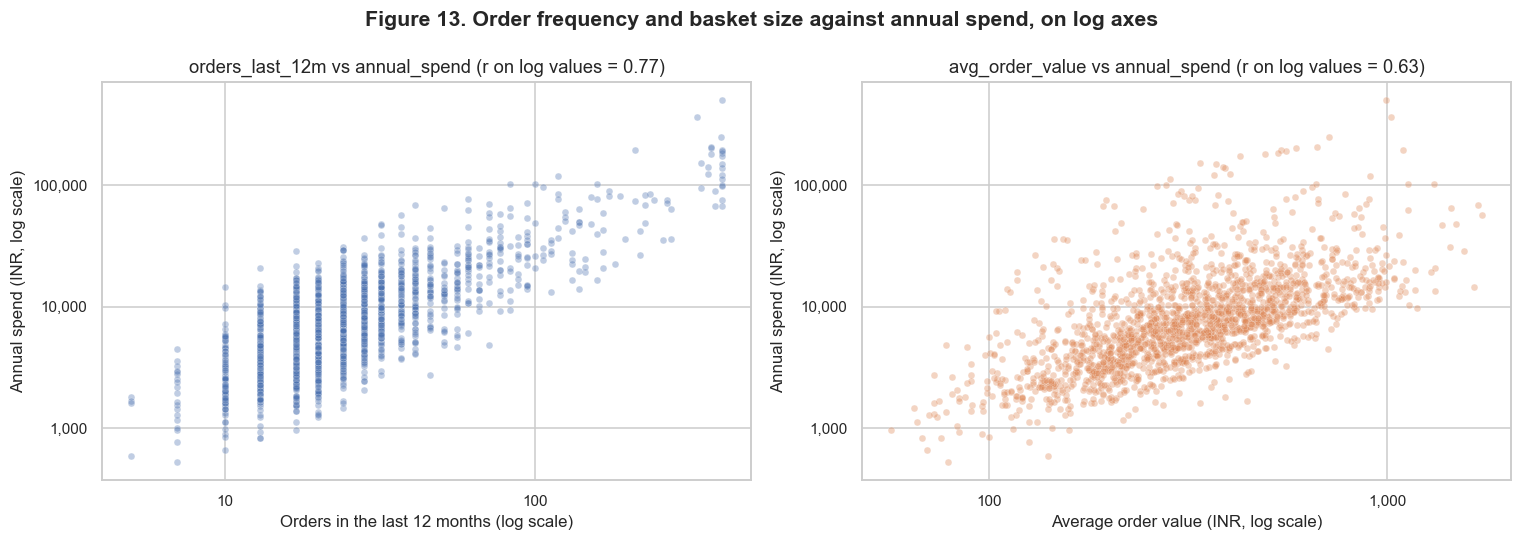

In [30]:
# Figure 13: the two drivers of spend on log axes, where the heavy tail no longer hides the pattern
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, label, colour in [
    (axes[0], "orders_last_12m", "Orders in the last 12 months (log scale)", BLUE),
    (axes[1], "avg_order_value", "Average order value (INR, log scale)", ORANGE),
]:
    sns.scatterplot(data=recorded, x=col, y="annual_spend", alpha=0.35, s=20, color=colour, ax=ax)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    r_log = np.log(recorded[col]).corr(np.log(recorded["annual_spend"]))
    ax.set_title(f"{col} vs annual_spend (r on log values = {r_log:.2f})")
    ax.set_xlabel(label)
    ax.set_ylabel("Annual spend (INR, log scale)")
fig.suptitle("Figure 13. Order frequency and basket size against annual spend, on log axes")
plt.tight_layout()
plt.show()

### Findings on relationships

**Which variable has the strongest relationship with `annual_spend`?** `orders_last_12m`, with a Pearson correlation of 0.72. The answer holds under every check in 4.6: it is about 0.80 with the largest account left out and 0.77 to 0.78 on log values.

Basket size is the second driver, and the headline matrix understates it for two reasons. The first is one imputed row: the largest spender has no recorded basket and was filled with the tier median of 325 rupees. With that account left out, the correlation rises from 0.25 to 0.33. The second and larger reason is the heavy tail. On log values the correlation is 0.61 for all customers and 0.63 for those with a recorded basket. That is what the arithmetic predicts, because annual spend is close to orders multiplied by basket size (the product has a correlation of 0.99 with spend). Frequency carries more weight because order counts differ far more between customers (5 to 400) than baskets do (57 to 1,729 rupees). Figure 13 shows both relationships once the axes are on a log scale.

App usage has a modest link that Pearson nearly hides (0.08). Median annual spend rises from 5,538 rupees in the least active third of customers to about 9,270 in the most active third. Everything else in the matrix (city tier, age, tenure, discount, recency, delivery time, rating) is within ±0.03 of zero.

**Other relationships worth noting**

- Membership level goes with higher spend. The median rises at every step, from 5,875 rupees for Basic to 12,362 for Platinum.
- Gender, device and acquisition channel make little difference. Median annual spend is between about 6,100 and 8,200 rupees in every group, close to the overall median of 7,142.
- App sessions and orders have a Pearson correlation of only 0.08, but the median number of orders rises from 17 to 28 between the least and most active thirds. The link is real and modest.
- Delivery time has almost no linear relationship with the rating a customer gives (−0.02 among customers who rated). Read that with section 1.2 in mind: customers with slow deliveries often have no rating at all, so the ratings on file say little about them.
- Delivery is slower outside the metros. The median is 30.6 minutes in tier 1, 32.6 in tier 2 and 36.6 in tier 3, and the share of customers averaging more than 45 minutes is 12% in tier 1 against about one in five in tiers 2 and 3. Baskets also get a little smaller outside the metros (correlation of −0.12 with tier).
- Older customers use slightly smaller discounts (−0.25).
- The line plots need care. The file holds only customers with at least 12 months of tenure and orders in the past year, so the monthly counts show how many of today's established customers joined in each month. They do not show how many people signed up. Read that way, the cohorts are even in size (about 59 a month, between roughly 40 and 70; 724 from 2023, 688 from 2024, 581 from the first ten months of 2025). Average delivery time shows no pattern by joining date. The monthly averages run from 32 to 37 minutes, which is about the spread that chance alone would produce with 59 customers a month.

**Does correlation prove causation?** No. A correlation says two variables move together in this data. It does not say which one causes the other, or whether something else drives both. Orders and spend are a special case, because spend is close to orders multiplied by basket size, so that relationship is arithmetic. Membership is a better example of the trap. Platinum members spend more, but the file does not say how tiers are assigned. If heavy users are the ones who end up in higher tiers, the tier is a result of spending and not a cause of it, and moving a customer up a tier would not by itself raise their spend. An experiment would be needed to find out. The checks in 4.6 add a second caution: Pearson correlation only measures straight-line relationships, and in data with a heavy tail a single account can move it.

## Task 5: Encoding categorical variables

Most numerical methods need numbers, so text categories have to be converted. The right method depends on whether the categories have an order and how many of them there are.

| Technique | Applied to | scikit-learn class | Reason |
|---|---|---|---|
| Label (ordinal) encoding | `membership` | `OrdinalEncoder` | Basic < Silver < Gold < Platinum is a real order |
| One-hot encoding | `device_type`, `acquisition_channel` | `OneHotEncoder` | No order, few categories |
| Target encoding | `city` | `TargetEncoder` | No order, 10 categories |

The encoders come from `sklearn.preprocessing`. Calling `fit` on an encoder only records the categories and, for the target encoder, each city's mean spend. No model is trained. The brief names the pandas route (a mapping for `membership`, `pd.get_dummies` with `drop_first`, and a city mean), so the cell runs that as well and confirms that both routes give identical columns.

In [31]:
# Work on a small copy so the cleaned dataset keeps its original, readable columns
enc = df[["customer_id", "membership", "device_type", "acquisition_channel", "city", "annual_spend"]].copy()

# --- 1. Label (ordinal) encoding for membership --------------------------------
# OrdinalEncoder is given the order explicitly. Left to itself it would sort the levels
# alphabetically (Basic, Gold, Platinum, Silver), and so would LabelEncoder.
ordinal = OrdinalEncoder(categories=[membership_order], dtype=int)
enc["membership_encoded"] = ordinal.fit_transform(enc[["membership"]]).ravel()
membership_map = {level: code for code, level in enumerate(ordinal.categories_[0])}
print("Membership mapping:", membership_map)

# --- 2. One-hot encoding for device_type and acquisition_channel ---------------
nominal = ["device_type", "acquisition_channel"]
ohe_all = OneHotEncoder(sparse_output=False, dtype=int).set_output(transform="pandas")                   # every category
ohe = OneHotEncoder(drop="first", sparse_output=False, dtype=int).set_output(transform="pandas")     # one dropped per variable
onehot_all = ohe_all.fit_transform(enc[nominal])
onehot = ohe.fit_transform(enc[nominal])
print(f"\nOne-hot columns with every category kept: {onehot_all.shape[1]}")
print(f"One-hot columns with drop='first'        : {onehot.shape[1]} -> {list(onehot.columns)}")

# The dummy variable trap: the full set of device columns always adds up to 1
device_cols = [c for c in onehot_all.columns if c.startswith("device_type_")]
print("Row sums of the three device columns:", onehot_all[device_cols].sum(axis=1).unique())

# --- 3. Target encoding for city -----------------------------------------------
# fit() and then transform() with smooth=0 returns each city's plain mean annual_spend.
# fit_transform() would shrink and cross-fit the means, which is what a model needs (see the findings).
target = TargetEncoder(target_type="continuous", smooth=0.0)
target.fit(enc[["city"]], enc["annual_spend"])
city_encoded = target.transform(enc[["city"]]).ravel()
enc["city_target_encoded"] = city_encoded.round(0)          # rounded to whole rupees for display

# For comparison only: LabelEncoder sorts the names alphabetically, so this is what it would do to city
enc["city_alphabetical_code"] = LabelEncoder().fit_transform(enc["city"])

# --- 4. Check against the pandas methods named in the brief --------------------
pandas_label = enc["membership"].map({"Basic": 0, "Silver": 1, "Gold": 2, "Platinum": 3})
pandas_onehot = pd.get_dummies(enc[nominal], drop_first=True, dtype=int)
pandas_target = enc["city"].map(df.groupby("city")["annual_spend"].mean())
same_onehot = (list(onehot.columns) == list(pandas_onehot.columns)
               and bool((onehot.to_numpy() == pandas_onehot.to_numpy()).all()))
print("\nSame result as the pandas methods in the brief, on all", len(enc), "rows:")
print("  label encoding   (dictionary and map)            :", bool((enc["membership_encoded"] == pandas_label).all()))
print("  one-hot encoding (pd.get_dummies, drop_first=True):", same_onehot)
print("  target encoding  (city mean and map)             :", bool(np.allclose(city_encoded, pandas_target)))

Membership mapping: {'Basic': 0, 'Silver': 1, 'Gold': 2, 'Platinum': 3}

One-hot columns with every category kept: 8
One-hot columns with drop='first'        : 6 -> ['device_type_Web', 'device_type_iOS', 'acquisition_channel_Organic', 'acquisition_channel_Paid Social', 'acquisition_channel_Referral', 'acquisition_channel_Search Ads']
Row sums of the three device columns: [1]

Same result as the pandas methods in the brief, on all 2000 rows:
  label encoding   (dictionary and map)            : True
  one-hot encoding (pd.get_dummies, drop_first=True): True
  target encoding  (city mean and map)             : True


In [32]:
# City lookup: alphabetical code vs target encoding, with the median and customer count for context
city_table = df.groupby("city").agg(
    city_tier=("city_tier", "first"),
    customers=("customer_id", "count"),
    target_encoding_mean_spend=("annual_spend", "mean"),
    median_spend=("annual_spend", "median"),
)
city_table.insert(0, "alphabetical_code", range(len(city_table)))
display(city_table.sort_values("target_encoding_mean_spend", ascending=False))

# Original and encoded columns side by side for the first few customers
side_by_side = pd.concat([
    enc[["customer_id", "membership", "membership_encoded", "device_type"]],
    onehot[[c for c in onehot.columns if c.startswith("device_type_")]],
    enc[["acquisition_channel"]],
    onehot[[c for c in onehot.columns if c.startswith("acquisition_channel_")]],
    enc[["city", "city_alphabetical_code", "city_target_encoded"]],
], axis=1)
side_by_side.head(8)

,alphabetical_code,city_tier,customers,target_encoding_mean_spend,median_spend
city,,,,,
Hyderabad,2,1,241,"18,300.34","7,587.00"
Kochi,5,3,105,"15,739.56","7,770.00"
Nagpur,8,3,104,"15,515.56","7,415.00"
Lucknow,6,2,148,"13,939.90","7,519.00"
Delhi,1,1,300,"12,152.45","7,147.50"
Mumbai,7,1,320,"12,020.80","7,095.00"
Bengaluru,0,1,294,"12,004.01","7,095.50"
Pune,9,2,198,"10,929.08","6,840.00"
Indore,3,3,147,"10,732.65","6,461.00"


,customer_id,membership,membership_encoded,device_type,device_type_Web,device_type_iOS,acquisition_channel,acquisition_channel_Organic,acquisition_channel_Paid Social,acquisition_channel_Referral,acquisition_channel_Search Ads,city,city_alphabetical_code,city_target_encoded
0,QB100000,Basic,0,Android,0,0,Referral,0,0,1,0,Lucknow,6,"13,940.00"
1,QB100001,Basic,0,iOS,0,1,Influencer,0,0,0,0,Bengaluru,0,"12,004.00"
2,QB100002,Basic,0,iOS,0,1,Referral,0,0,1,0,Indore,3,"10,733.00"
3,QB100003,Basic,0,Android,0,0,Paid Social,0,1,0,0,Jaipur,4,"10,411.00"
4,QB100004,Basic,0,Android,0,0,Search Ads,0,0,0,1,Mumbai,7,"12,021.00"
5,QB100005,Basic,0,Android,0,0,Paid Social,0,1,0,0,Kochi,5,"15,740.00"
6,QB100006,Silver,1,iOS,0,1,Search Ads,0,0,0,1,Lucknow,6,"13,940.00"
7,QB100007,Basic,0,iOS,0,1,Organic,1,0,0,0,Lucknow,6,"13,940.00"


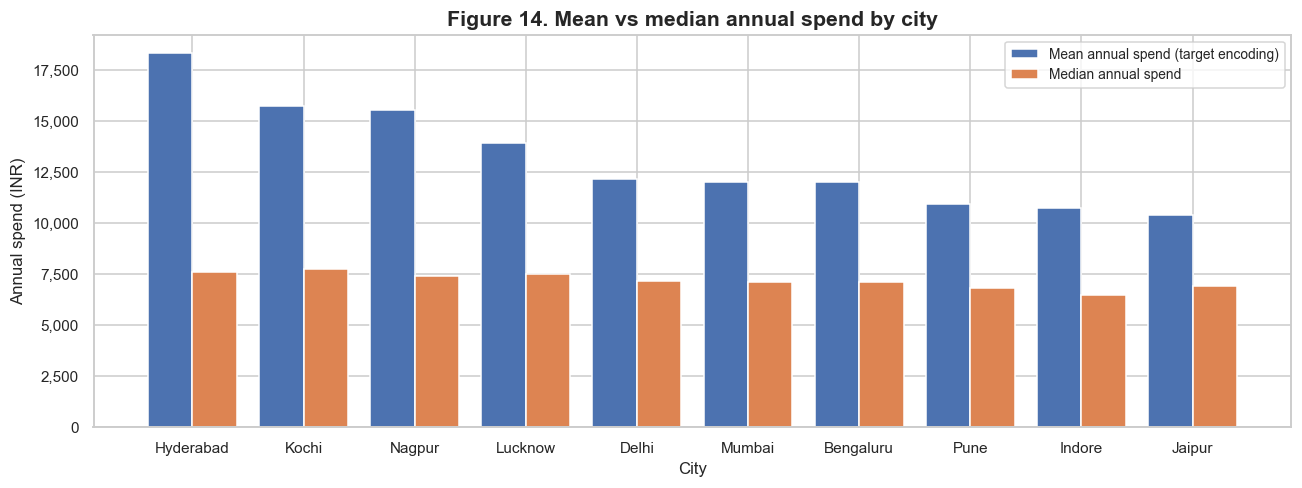

In [33]:
# Figure 14: target encoding of city (mean spend) next to the median, to show how fragile the mean is
plot_cities = city_table.sort_values("target_encoding_mean_spend", ascending=False)
fig, ax = plt.subplots(figsize=(12, 4.6))
x = np.arange(len(plot_cities))
ax.bar(x - 0.2, plot_cities["target_encoding_mean_spend"], width=0.4, color=BLUE, label="Mean annual spend (target encoding)")
ax.bar(x + 0.2, plot_cities["median_spend"], width=0.4, color=ORANGE, label="Median annual spend")
ax.set_xticks(x)
ax.set_xticklabels(plot_cities.index)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_title("Figure 14. Mean vs median annual spend by city", fontsize=14, fontweight="bold")
ax.set_xlabel("City")
ax.set_ylabel("Annual spend (INR)")
ax.legend()
plt.tight_layout()
plt.show()

### Findings and discussion on encoding

**Label encoding fits `membership`** because the levels have a real order, and the codes 0 to 3 preserve it. The one assumption it adds is that the steps are equally spaced, which is acceptable for a simple ordinal code. `OrdinalEncoder` is used with the order written out. `LabelEncoder` would be the wrong class here: it sorts the levels alphabetically (Basic, Gold, Platinum, Silver), which puts Silver above Platinum, and scikit-learn intends it for target labels and not for features.

**One-hot encoding and the dummy variable trap.** `OneHotEncoder` gives each category its own 0/1 column, as `pd.get_dummies` does. With all categories kept, the columns for one variable always add up to 1, so any one of them can be worked out from the others. That redundancy (perfect multicollinearity) breaks linear models, and it is called the dummy variable trap. `drop="first"` (`drop_first=True` in `pd.get_dummies`) removes one column per variable. The dropped category becomes the baseline: a customer with 0 in both `device_type_iOS` and `device_type_Web` is an Android user. Eight columns become six with no information lost.

**Why alphabetical label encoding of `city` would be misleading.** `LabelEncoder` sorts the names, so it would give Bengaluru 0, Delhi 1, Hyderabad 2 and so on up to Pune 9. Any calculation using those numbers would treat Pune as "more" than Bengaluru and Delhi as sitting between Bengaluru and Hyderabad. The alphabet has nothing to do with customers, so the encoding would invent an order and distances that do not exist.

**Why one-hot on 10 cities is wide.** It would add 9 or 10 mostly-zero columns for one variable. That is manageable here, but the approach scales badly: 500 cities would mean 500 columns, each with very few customers behind it.

**The risk of target encoding.** Target encoding replaces each city with its mean `annual_spend`, which gives one compact, meaningful column. The risk is leakage: the feature is built from the very thing we want to explain. Each customer's own spend is part of their city's mean, so the feature already contains a piece of the answer, and any model evaluated on the same rows would look better than it really is. The usual protection is to compute the means on training data only, or out-of-fold. scikit-learn builds that in: `TargetEncoder.fit_transform` computes the means out-of-fold and shrinks each city towards the overall mean. This notebook trains no model, so it calls `fit` and then `transform` with `smooth=0`, which returns the plain city mean and keeps the numbers easy to check.

**The target encoding is also fragile here.** Hyderabad has the highest mean spend (about 18,300 rupees) but its median (7,587) is in line with every other city. The mean is being lifted by a few very large accounts, including the single biggest spender in the file. Take that one account out and Hyderabad's mean falls to about 14,800, below Kochi and Nagpur. Figure 14 shows the pattern: the medians are nearly flat across cities while the means jump around. With only 104 to 320 customers per city, a mean-based encoding mostly records where a few whales happen to live.

## Task 6: Central tendency and percentiles

### 6.1 Mean, median and mode

In [34]:
def describe_centre(col):
    """Mean, median and mode for one numeric column of the cleaned data."""
    s = df[col]
    counts = s.value_counts()
    observed_counts = df_pre_impute[col].value_counts()   # before imputation added copies of the median
    return {
        "mean": s.mean(),
        "median": s.median(),
        "mode": counts.index[0],
        "customers at the mode": int(counts.iloc[0]),
        "values tied for the mode": int((counts == counts.iloc[0]).sum()),
        "mode before imputation": observed_counts.index[0],
        "mean / median": s.mean() / s.median(),
    }


centre = pd.DataFrame({col: describe_centre(col) for col in ["age", "orders_last_12m", "annual_spend"]}).T
centre = centre.astype({"customers at the mode": int, "values tied for the mode": int})   # counts, not decimals
display(centre)

# membership is a category, so only the mode is meaningful
membership_counts = df["membership"].value_counts().reindex(membership_order)
print(f"membership mode: {df['membership'].mode()[0]} "
      f"({membership_counts['Basic']:,} of {len(df):,} customers, {membership_counts['Basic'] / len(df):.0%})")
print(membership_counts.to_string())

,mean,median,mode,customers at the mode,values tied for the mode,mode before imputation,mean / median
age,31.90,32.00,32.00,236,1,31.00,1.00
orders_last_12m,34.90,24.00,17.00,366,1,17.00,1.45
annual_spend,"12,995.85","7,142.00","4,741.00",3,6,"4,741.00",1.82


membership mode: Basic (1,179 of 2,000 customers, 59%)
membership
Basic       1179
Silver       436
Gold         237
Platinum     148


### 6.2 Why the mean is so much larger than the median for `annual_spend`

In [35]:
spend = df["annual_spend"]
mean_spend, median_spend = spend.mean(), spend.median()

print(f"Mean annual spend   : {mean_spend:,.0f} INR")
print(f"Median annual spend : {median_spend:,.0f} INR")
print(f"The mean is {mean_spend / median_spend:.2f} times the median")
print(f"Customers who spend less than the mean: {(spend < mean_spend).mean():.1%}")

# How much the top customers move the mean
for k in [1, 20, 100]:
    trimmed_mean = spend.sort_values(ascending=False).iloc[k:].mean()
    print(f"Mean without the top {k:>3} customers: {trimmed_mean:,.0f} INR")

Mean annual spend   : 12,996 INR
Median annual spend : 7,142 INR
The mean is 1.82 times the median
Customers who spend less than the mean: 75.6%
Mean without the top   1 customers: 12,574 INR
Mean without the top  20 customers: 10,819 INR
Mean without the top 100 customers: 8,709 INR


### 6.3 Percentiles

In [36]:
percentile_levels = [10, 25, 50, 75, 90, 95, 99]

# np.percentile on the two columns the brief asks for
percentiles = pd.DataFrame(
    {col: np.percentile(df[col], percentile_levels) for col in ["delivery_time_min", "annual_spend"]},
    index=[f"P{p}" for p in percentile_levels],
)
display(percentiles.T)

p90_delivery = percentiles.loc["P90", "delivery_time_min"]
print(f"90% of customers have an average delivery time of {p90_delivery:.1f} minutes or less.")

,P10,P25,P50,P75,P90,P95,P99
delivery_time_min,22.10,26.50,32.25,40.10,49.21,55.40,68.60
annual_spend,"2,508.60","4,085.75","7,142.00","12,781.25","22,453.70","35,355.25","109,149.78"


90% of customers have an average delivery time of 49.2 minutes or less.


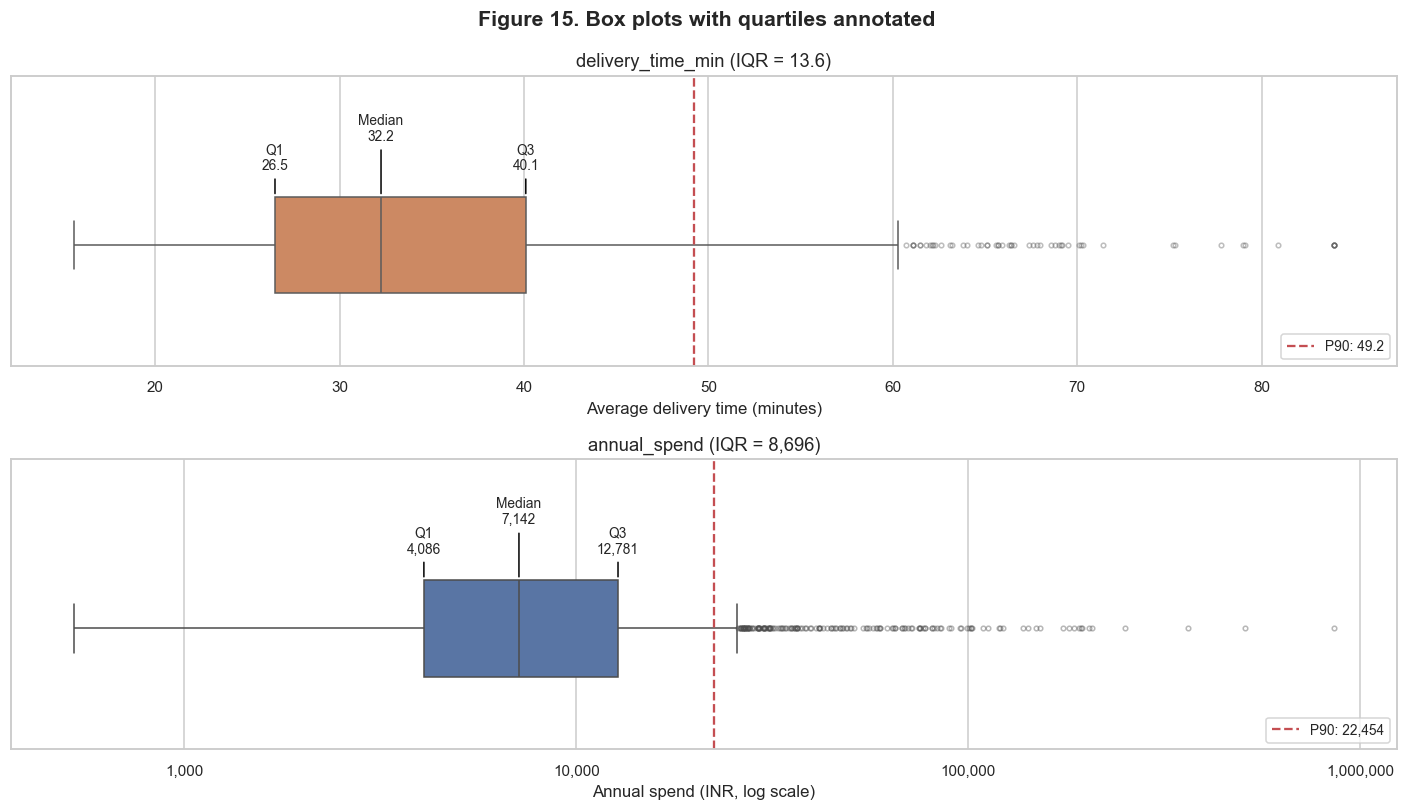

In [37]:
def annotated_box(ax, s, title, xlabel, color, fmt, log=False):
    """Horizontal box plot with Q1, median, Q3 and P90 labelled."""
    sns.boxplot(x=s, color=color, width=0.4, flierprops={"marker": "o", "markersize": 3, "alpha": 0.4}, ax=ax)
    q1, q2, q3, p90 = np.percentile(s, [25, 50, 75, 90])
    for value, label, y in [(q1, "Q1", -0.30), (q2, "Median", -0.42), (q3, "Q3", -0.30)]:
        ax.annotate(f"{label}\n{fmt.format(value)}", xy=(value, -0.2), xytext=(value, y),
                    ha="center", va="bottom", fontsize=9, arrowprops={"arrowstyle": "-", "color": "black"})
    ax.axvline(p90, color=RED, ls="--", lw=1.5, label=f"P90: {fmt.format(p90)}")
    if log:
        ax.set_xscale("log")
        ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    ax.set_ylim(0.5, -0.7)
    ax.set_title(f"{title} (IQR = {fmt.format(q3 - q1)})")
    ax.set_xlabel(xlabel)
    ax.legend(loc="lower right")


# Figure 15: annotated box plots
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5))
annotated_box(axes[0], df["delivery_time_min"], "delivery_time_min", "Average delivery time (minutes)", ORANGE, "{:.1f}")
annotated_box(axes[1], df["annual_spend"], "annual_spend", "Annual spend (INR, log scale)", BLUE, "{:,.0f}", log=True)
fig.suptitle("Figure 15. Box plots with quartiles annotated")
plt.tight_layout()
plt.show()

### Findings on central tendency and percentiles

- Age is symmetric: the mean (31.9), median (32) and mode agree. The mode before imputation was 31. It reads 32 in the cleaned data only because 142 imputed values were placed there.
- Orders: the mean is 34.9 orders a year, the median is 24 and the most common value is 17 (366 customers). A typical customer orders about twice a month. The column is bucketed, and 47% of customers sit on 17, 20 or 24.
- Annual spend: the mean is 12,996 rupees and the median is 7,142, so the mean is 1.82 times the median. About 76% of customers spend less than the "average". Taking out just the top 20 customers (1% of the base) drops the mean from 12,996 to about 10,819. Spend has no useful mode: nearly every customer has a different total, and six different values tie as the most repeated, at three customers each. The one in the table is simply the first of them.
- Membership: the mode is Basic, with 1,179 customers (59%).

**What mean ≫ median tells the business.** The average customer is not a typical customer. A small group of very heavy users lifts the mean well above what most people spend. Planning that uses the mean, for example budgeting an acquisition cost against "average annual spend of 13,000", will overestimate what an ordinary new customer brings in. The median of about 7,100 is the realistic figure for a typical customer, and the heavy users should be planned for as a separate group.

**"What delivery time do 90% of customers experience or better?"** About 49 minutes. Nine in ten customers have an average delivery time of 49 minutes or less, and the slowest 10% average more than that. Half of all customers average 32 minutes or less, and the slowest 1% average more than 68 minutes. These percentiles use the cleaned column. On observed values alone they are slightly higher (a P90 of 49.5 and a P95 of 56.0 minutes), as Task 8 shows.

The annual spend percentiles show the tail: P50 is 7,142 rupees, P90 is about 22,500, and P99 is about 109,000, fifteen times the median.

## Task 7: Pareto distribution and the 80/20 rule

The 80/20 idea says that roughly 20% of customers produce 80% of revenue. This section measures what the split is at QuickBite.

### 7.1 Cumulative revenue share

In [38]:
# Sort customers from biggest to smallest spender
spend_sorted = df["annual_spend"].sort_values(ascending=False).reset_index(drop=True)
n = len(spend_sorted)
total_revenue = spend_sorted.sum()

cum_revenue_share = spend_sorted.cumsum() / total_revenue     # share of revenue from the top k customers
cum_customer_share = np.arange(1, n + 1) / n                  # share of customers that the top k represent


def top_share(pct):
    """Revenue share contributed by the top pct% of customers."""
    k = int(round(n * pct / 100))
    return cum_revenue_share.iloc[k - 1]


def customers_needed(revenue_target):
    """Smallest share of customers (biggest first) needed to reach a revenue share."""
    k = int(np.searchsorted(cum_revenue_share.values, revenue_target)) + 1
    return k, k / n


print(f"Total annual revenue in the extract: {total_revenue:,.0f} INR from {n:,} customers\n")
for pct in [1, 5, 10, 20, 50]:
    print(f"Top {pct:>2}% of customers ({int(round(n * pct / 100)):>4}) -> {top_share(pct):.1%} of revenue")

print()
for target in [0.5, 0.8]:
    k, share = customers_needed(target)
    print(f"{target:.0%} of revenue comes from the top {k} customers ({share:.1%} of the base)")

print(f"\nBottom 50% of customers -> {1 - top_share(50):.1%} of revenue")

print(f"Largest single account -> {spend_sorted.iloc[0] / total_revenue:.1%} of revenue")

Total annual revenue in the extract: 25,991,704 INR from 2,000 customers

Top  1% of customers (  20) -> 17.6% of revenue
Top  5% of customers ( 100) -> 36.3% of revenue
Top 10% of customers ( 200) -> 46.9% of revenue
Top 20% of customers ( 400) -> 60.6% of revenue
Top 50% of customers (1000) -> 84.1% of revenue

50% of revenue comes from the top 238 customers (11.9% of the base)
80% of revenue comes from the top 862 customers (43.1% of the base)

Bottom 50% of customers -> 15.9% of revenue
Largest single account -> 3.3% of revenue


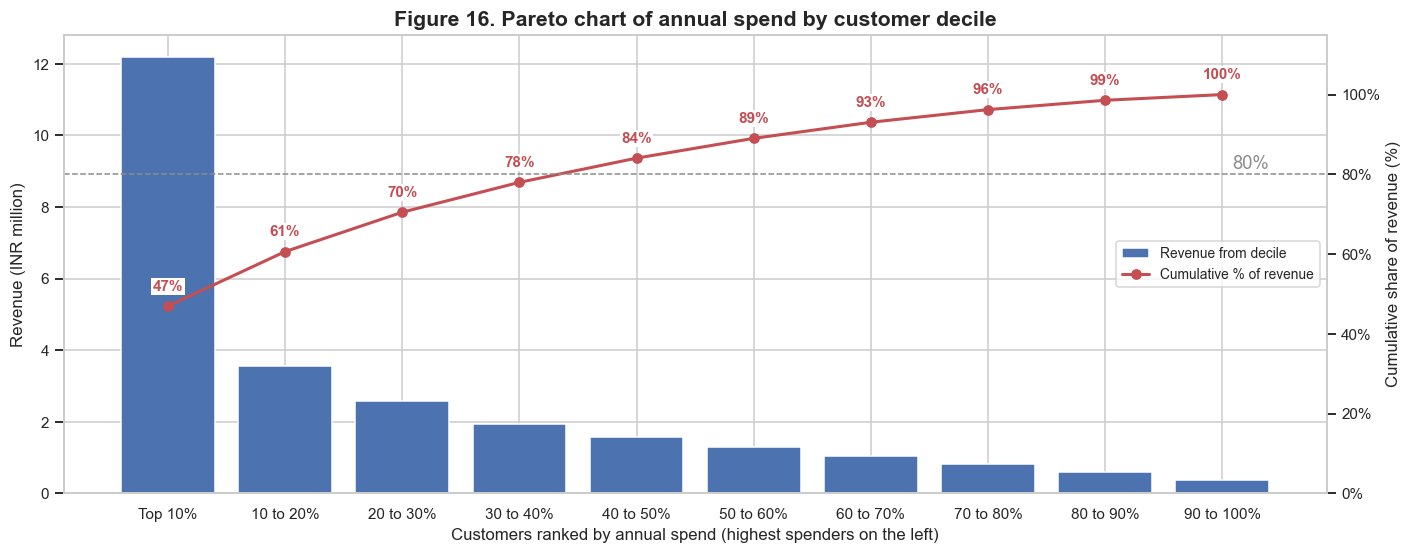

In [39]:
# Figure 16: Pareto chart. Bars = revenue of each customer decile, line = cumulative share.
decile = np.minimum(np.arange(n) * 10 // n, 9) + 1            # 1 = top 10% of spenders (works for any n)
decile_revenue = spend_sorted.groupby(decile).sum()
decile_cum_pct = decile_revenue.cumsum() / total_revenue * 100
decile_labels = [f"Top 10%"] + [f"{(d - 1) * 10} to {d * 10}%" for d in range(2, 11)]

fig, ax = plt.subplots(figsize=(13, 5.2))
ax.bar(decile_labels, decile_revenue / 1e6, color=BLUE, label="Revenue from decile")
ax.set_xlabel("Customers ranked by annual spend (highest spenders on the left)")
ax.set_ylabel("Revenue (INR million)")
ax.set_title("Figure 16. Pareto chart of annual spend by customer decile", fontsize=14, fontweight="bold")

ax2 = ax.twinx()                                              # second axis for the cumulative line
ax2.plot(decile_labels, decile_cum_pct, color=RED, marker="o", lw=2, label="Cumulative % of revenue")
ax2.axhline(80, color=GREY, ls="--", lw=1)
ax2.text(9.4, 81.5, "80%", color=GREY, ha="right")
for i, v in enumerate(decile_cum_pct):
    ax2.text(i, v + 4, f"{v:.0f}%", ha="center", fontsize=10, color=RED, fontweight="bold",
             bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
ax2.set_ylim(0, 115)
ax2.set_ylabel("Cumulative share of revenue (%)")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.grid(False)

lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2, loc="center right")
plt.tight_layout()
plt.show()

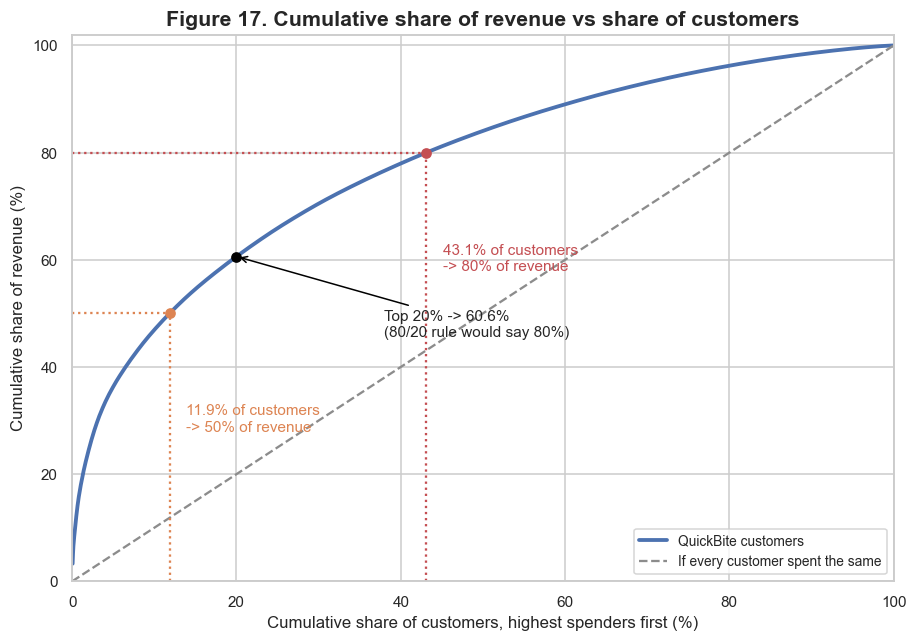

In [40]:
# Figure 17: cumulative share curve with the 50% and 80% points marked
k50, share50 = customers_needed(0.5)
k80, share80 = customers_needed(0.8)

fig, ax = plt.subplots(figsize=(8.5, 6))
ax.plot(cum_customer_share * 100, cum_revenue_share * 100, color=BLUE, lw=2.5, label="QuickBite customers")
ax.plot([0, 100], [0, 100], color=GREY, ls="--", label="If every customer spent the same")

for share, target, colour in [(share50, 50, ORANGE), (share80, 80, RED)]:
    ax.plot([share * 100, share * 100], [0, target], color=colour, ls=":", lw=1.5)
    ax.plot([0, share * 100], [target, target], color=colour, ls=":", lw=1.5)
    ax.scatter([share * 100], [target], color=colour, zorder=5)
    ax.annotate(f"{share:.1%} of customers\n-> {target}% of revenue", xy=(share * 100, target),
                xytext=(share * 100 + 2, target - 22), fontsize=10, color=colour)

ax.scatter([20], [top_share(20) * 100], color="black", zorder=5)
ax.annotate(f"Top 20% -> {top_share(20):.1%}\n(80/20 rule would say 80%)", xy=(20, top_share(20) * 100),
            xytext=(38, top_share(20) * 100 - 15), fontsize=10, arrowprops={"arrowstyle": "->", "color": "black"})

ax.set_title("Figure 17. Cumulative share of revenue vs share of customers", fontsize=14, fontweight="bold")
ax.set_xlabel("Cumulative share of customers, highest spenders first (%)")
ax.set_ylabel("Cumulative share of revenue (%)")
ax.set_xlim(0, 100)
ax.set_ylim(0, 102)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 7.2 Two checks: the largest account, and order counts

The first check asks whether the result depends on the single largest account, which Task 2 marked for confirmation. The second repeats the concentration measure for `orders_last_12m`, the other heavy-tailed variable from Task 3.

In [41]:
# One function so the same concentration measures can be run on any column

def concentration(values):
    """How concentrated a column is: shares held by the top customers, all in %."""
    v = np.sort(np.asarray(values, dtype=float))[::-1]
    cum = np.cumsum(v) / v.sum()
    m = len(v)
    return {
        "top 1% share": cum[int(round(m * 0.01)) - 1] * 100,
        "top 10% share": cum[int(round(m * 0.10)) - 1] * 100,
        "top 20% share": cum[int(round(m * 0.20)) - 1] * 100,
        "% of customers for half the total": (np.searchsorted(cum, 0.5) + 1) / m * 100,
        "% of customers for 80% of the total": (np.searchsorted(cum, 0.8) + 1) / m * 100,
    }


top_id = df["annual_spend"].idxmax()
no_top = df.drop(index=top_id)

print("Concentration (all figures in %):")
display(pd.DataFrame({
    "annual_spend": concentration(df["annual_spend"]),
    "annual_spend, largest account left out": concentration(no_top["annual_spend"]),
    "orders_last_12m": concentration(df["orders_last_12m"]),
}).T)


def spend_summary(data):
    """The statistics most exposed to one very large account."""
    return {
        "mean annual spend": data["annual_spend"].mean(),
        "skewness of annual spend": data["annual_spend"].skew(),
        "correlation, orders vs spend": data["orders_last_12m"].corr(data["annual_spend"]),
        "mean spend in Hyderabad": data.loc[data["city"] == "Hyderabad", "annual_spend"].mean(),
    }


print("What else the largest account moves:")
display(pd.DataFrame({"all customers": spend_summary(df), "largest account left out": spend_summary(no_top)}))

Concentration (all figures in %):


,top 1% share,top 10% share,top 20% share,% of customers for half the total,% of customers for 80% of the total
annual_spend,17.58,46.94,60.61,11.90,43.10
"annual_spend, largest account left out",15.21,45.22,59.33,12.91,44.12
orders_last_12m,11.27,40.42,53.27,17.05,55.30


What else the largest account moves:


,all customers,largest account left out
mean annual spend,"12,995.85","12,574.42"
skewness of annual spend,15.24,9.43
"correlation, orders vs spend",0.72,0.80
mean spend in Hyderabad,"18,300.34","14,812.25"


### 7.3 Who are the top 20%?

In [42]:
# Compare the top 20% of spenders with everyone else
threshold_top20 = df["annual_spend"].quantile(0.80)
df_seg = df.assign(segment=np.where(df["annual_spend"] >= threshold_top20, "Top 20%", "Other 80%"),
                   recorded_basket=df_pre_impute["avg_order_value"])     # basket size before imputation
print(f"A customer enters the top 20% at {threshold_top20:,.0f} INR a year\n")

profile = df_seg.groupby("segment").agg(
    customers=("customer_id", "count"),
    median_spend=("annual_spend", "median"),
    median_orders=("orders_last_12m", "median"),
    median_recorded_basket=("recorded_basket", "median"),
    median_app_sessions=("app_sessions_per_month", "median"),
    median_delivery_time=("delivery_time_min", "median"),
    pct_above_basic=("membership", lambda s: (s != "Basic").mean() * 100),
).reindex(["Top 20%", "Other 80%"])
display(profile)

# Membership mix inside each segment (% of the segment)
mix = pd.crosstab(df_seg["segment"], df_seg["membership"], normalize="index").reindex(
    index=["Top 20%", "Other 80%"], columns=membership_order) * 100
print("Membership mix by segment (%):")
display(mix)

# The other direction: what share of each tier is in the top 20% of spenders?
tier_in_top = pd.crosstab(df_seg["membership"], df_seg["segment"], normalize="index")["Top 20%"].reindex(membership_order) * 100
print("Share of each membership tier that is in the top 20% (%):")
print(tier_in_top.round(1).to_string())
print()

# Revenue share by membership level
rev_by_membership = df.groupby("membership")["annual_spend"].sum().reindex(membership_order) / total_revenue * 100
print("Share of total revenue by membership level (%):")
print(rev_by_membership.round(1).to_string())

A customer enters the top 20% at 14,582 INR a year



,customers,median_spend,median_orders,median_recorded_basket,median_app_sessions,median_delivery_time,pct_above_basic
segment,,,,,,,
Top 20%,400,"22,472.50",46.00,492.00,15.00,32.00,55.25
Other 80%,1600,"5,827.00",20.00,287.00,13.00,32.25,37.50


Membership mix by segment (%):


membership,Basic,Silver,Gold,Platinum
segment,,,,
Top 20%,44.75,22.25,17.75,15.25
Other 80%,62.50,21.69,10.38,5.44


Share of each membership tier that is in the top 20% (%):
membership
Basic      15.20
Silver     20.40
Gold       30.00
Platinum   41.20

Share of total revenue by membership level (%):
membership
Basic      53.50
Silver     21.50
Gold       12.80
Platinum   12.20


### 7.4 Annual spend on a normal scale and a log scale

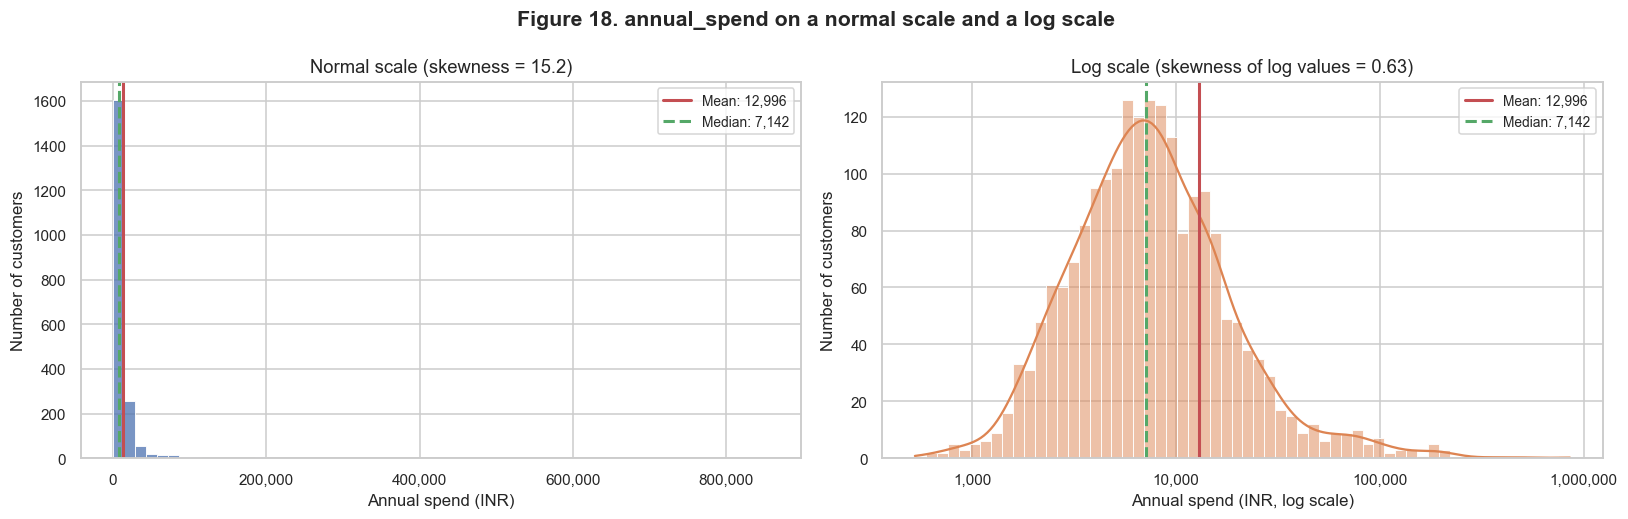

In [43]:
# Figure 18: the same variable on a linear axis and on a log axis
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

sns.histplot(df["annual_spend"], bins=60, color=BLUE, edgecolor="white", ax=axes[0])
axes[0].axvline(mean_spend, color=RED, lw=2, label=f"Mean: {mean_spend:,.0f}")
axes[0].axvline(median_spend, color=GREEN, lw=2, ls="--", label=f"Median: {median_spend:,.0f}")
axes[0].xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
axes[0].set_title(f"Normal scale (skewness = {df['annual_spend'].skew():.1f})")
axes[0].set_xlabel("Annual spend (INR)")
axes[0].set_ylabel("Number of customers")
axes[0].legend()

sns.histplot(df["annual_spend"], bins=60, log_scale=True, kde=True, color=ORANGE, edgecolor="white", ax=axes[1])
axes[1].axvline(mean_spend, color=RED, lw=2, label=f"Mean: {mean_spend:,.0f}")
axes[1].axvline(median_spend, color=GREEN, lw=2, ls="--", label=f"Median: {median_spend:,.0f}")
axes[1].xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
axes[1].set_title(f"Log scale (skewness of log values = {np.log(df['annual_spend']).skew():.2f})")
axes[1].set_xlabel("Annual spend (INR, log scale)")
axes[1].set_ylabel("Number of customers")
axes[1].legend()

fig.suptitle("Figure 18. annual_spend on a normal scale and a log scale")
plt.tight_layout()
plt.show()

### Findings on revenue concentration

- The top 20% of customers bring in 60.6% of revenue. That is strong concentration, but short of the classic 80/20. QuickBite is closer to 60/20.
- Half of all revenue comes from 11.9% of customers (238 people).
- Reaching 80% of revenue takes 43.1% of customers (862 people), not 20%.
- The top 1%, just 20 customers, bring in 17.6% of revenue. The single largest account is about 3.3% of the total on its own.
- The bottom half of the customer base contributes only 15.9% of revenue.

**Is this the Pareto principle?** The pattern is Pareto-like, but the numbers fall short of 80/20. The Pareto principle is the observation that a small share of causes produces most of the outcome, usually quoted as 20% of customers giving 80% of revenue. QuickBite has that kind of concentration, and the curve in Figure 17 bows well away from the equal-spend line. The strict split does not hold, as the figures above show. "About 60/20" is the accurate description.

The result does not depend on one account. With the largest spender left out, the top 20% still bring in 59.3%. That account does move other statistics: the skewness of spend falls from 15.2 to 9.4, the correlation between orders and spend rises from 0.72 to about 0.80, and Hyderabad's mean spend falls from about 18,300 to 14,800. The concentration finding is safe, and those statistics should be quoted with that caveat.

Orders are concentrated too, a little less than spend. The top 20% of customers by order count place 53.3% of all orders, and half of all orders come from 17% of customers.

Leadership's hunch is right: revenue depends on a small group of heavy users. The dependence is at the very top more than across the top fifth. Losing a handful of the largest accounts would be felt in the total.

**Who the top 20% are.** They order far more often (a median of 46 orders a year against 20) and their baskets are larger (a median recorded basket of 492 rupees against 287). Their app usage is slightly higher (15 sessions a month against 13) and their delivery times are the same as everyone else's. Tier is only a weak guide to who they are. A Platinum member is far more likely to be in the top 20% than a Basic member (41% against 15%), but Basic is by far the largest tier, so it still supplies 45% of the top group and 53% of all revenue.

**Normal scale vs log scale.** On the normal scale almost every customer is squeezed into the first few bars, and the rest of the axis is stretched out to reach a few very large accounts. The chart shows that a tail exists and little else. On the log scale each step along the axis is a multiplication (1,000, 10,000, 100,000), which spreads the crowded low end out and pulls the tail in. The bulk of the distribution then looks like a rough bell, centred near the median, with a tail on the right that is still fatter than a bell would have. Skewness falls from 15.2 to 0.63. So spend is close to log-normal for most customers, with a Pareto-like tail of heavy users on top.

## Task 8: PDF and CDF

- The PDF (probability density function) shows how dense the values are around each point. Where the curve is high, many customers have values near there. The height is not a probability by itself. The area under the curve between two points is.
- The CDF (cumulative distribution function) shows the share of values at or below each point. It starts at 0, ends at 1 and never goes down. Probabilities can be read straight off it.

Two things to keep in mind for this section:

- `delivery_time_min` is each customer's average delivery time. Every probability below is therefore about customers, for example "the share of customers whose average delivery time is above 45 minutes". The share of individual deliveries that run late cannot be worked out from this file.
- Observed values are used (1,920 customers, with the four extreme values capped). The 80 imputed values all sit on the median and would put an artificial step into both curves.

### 8.1 Delivery time

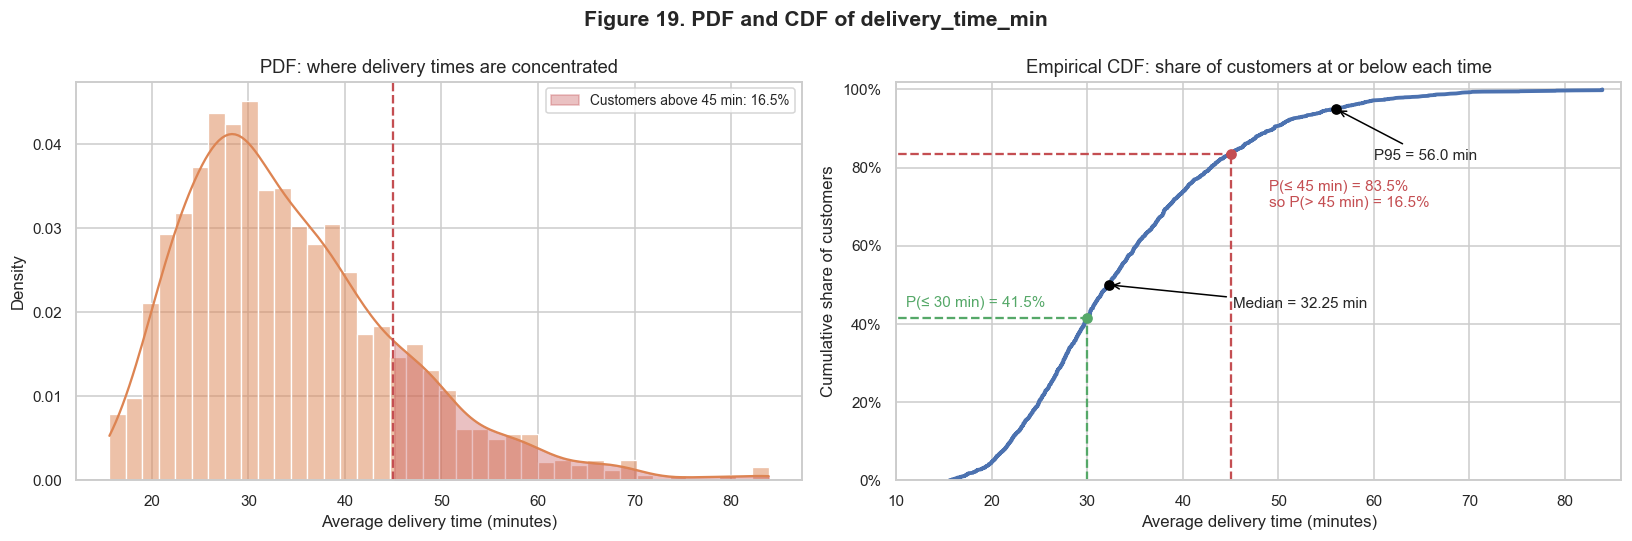

In [44]:
def ecdf(values):
    """Empirical CDF: sorted values on x, share of values at or below each one on y."""
    x = np.sort(np.asarray(values))
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y


def cdf_at(x_sorted, value):
    """P(X <= value) read from the empirical CDF."""
    return np.searchsorted(x_sorted, value, side="right") / len(x_sorted)


delivery = df_pre_impute["delivery_time_min"].dropna()        # observed values only
x_del, y_del = ecdf(delivery)

p_le_30 = cdf_at(x_del, 30)
p_gt_45 = 1 - cdf_at(x_del, 45)
median_del = np.percentile(delivery, 50)
p95_del = np.percentile(delivery, 95)

# Figure 19: PDF and CDF of delivery time
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# --- PDF: normalised histogram + KDE -------------------------------------------
sns.histplot(delivery, stat="density", bins=40, kde=True, color=ORANGE, edgecolor="white", alpha=0.5, ax=axes[0])
kx, ky = axes[0].lines[0].get_data()
axes[0].fill_between(kx, ky, where=kx > 45, color=RED, alpha=0.35, label=f"Customers above 45 min: {p_gt_45:.1%}")
axes[0].axvline(45, color=RED, ls="--", lw=1.5)
axes[0].set_title("PDF: where delivery times are concentrated")
axes[0].set_xlabel("Average delivery time (minutes)")
axes[0].set_ylabel("Density")
axes[0].legend()

# --- CDF: sorted values vs cumulative share ------------------------------------
axes[1].plot(x_del, y_del, color=BLUE, lw=2.5)
for value, prob, colour, text, text_xy in [
    (30, p_le_30, GREEN, f"P(≤ 30 min) = {p_le_30:.1%}", (11, p_le_30 + 0.03)),
    (45, 1 - p_gt_45, RED, f"P(≤ 45 min) = {1 - p_gt_45:.1%}\nso P(> 45 min) = {p_gt_45:.1%}", (49, 0.70)),
]:
    axes[1].plot([value, value], [0, prob], color=colour, ls="--", lw=1.5)
    axes[1].plot([0, value], [prob, prob], color=colour, ls="--", lw=1.5)
    axes[1].scatter([value], [prob], color=colour, zorder=5)
    axes[1].text(*text_xy, text, color=colour, fontsize=10)
axes[1].scatter([median_del, p95_del], [0.5, 0.95], color="black", zorder=5)
axes[1].annotate(f"Median = {median_del:.2f} min", xy=(median_del, 0.5), xytext=(median_del + 13, 0.44), fontsize=10,
                 arrowprops={"arrowstyle": "->", "color": "black"})
axes[1].annotate(f"P95 = {p95_del:.1f} min", xy=(p95_del, 0.95), xytext=(p95_del + 4, 0.82), fontsize=10,
                 arrowprops={"arrowstyle": "->", "color": "black"})
axes[1].set_xlim(10, x_del.max() + 2)
axes[1].set_ylim(0, 1.02)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set_title("Empirical CDF: share of customers at or below each time")
axes[1].set_xlabel("Average delivery time (minutes)")
axes[1].set_ylabel("Cumulative share of customers")

fig.suptitle("Figure 19. PDF and CDF of delivery_time_min")
plt.tight_layout()
plt.show()

In [45]:
# The answers, read from the CDF of observed values. The cleaned column, which includes the
# 80 imputed values, is shown next to it for comparison.
observed_delivery = delivery
cleaned_delivery = df["delivery_time_min"]
x_cl, _ = ecdf(cleaned_delivery)

answers = pd.DataFrame({
    f"observed values ({len(observed_delivery):,} customers)": {
        "P(average delivery ≤ 30 min)": f"{p_le_30:.1%}",
        "P(average delivery > 45 min)": f"{p_gt_45:.1%}",
        "Median (50th percentile)": f"{median_del:.2f} min",
        "95th percentile": f"{p95_del:.1f} min",
    },
    f"cleaned data incl. imputed ({len(cleaned_delivery):,} customers)": {
        "P(average delivery ≤ 30 min)": f"{cdf_at(x_cl, 30):.1%}",
        "P(average delivery > 45 min)": f"{1 - cdf_at(x_cl, 45):.1%}",
        "Median (50th percentile)": f"{np.percentile(cleaned_delivery, 50):.2f} min",
        "95th percentile": f"{np.percentile(cleaned_delivery, 95):.1f} min",
    },
})
display(answers)

# P(> 45 min) by city tier, observed values only
print("P(delivery > 45 min) by city tier, observed values:")
print((df_pre_impute.dropna(subset=["delivery_time_min"]).groupby("city_tier")["delivery_time_min"]
       .apply(lambda s: f"{(s > 45).mean():.1%}")).to_string())

,"observed values (1,920 customers)","cleaned data incl. imputed (2,000 customers)"
P(average delivery ≤ 30 min),41.5%,39.9%
P(average delivery > 45 min),16.5%,15.8%
Median (50th percentile),32.25 min,32.25 min
95th percentile,56.0 min,55.4 min


P(delivery > 45 min) by city tier, observed values:
city_tier
1    12.3%
2    22.1%
3    22.2%


### 8.2 Age, and a comparison of the two CDF shapes

To compare the shapes fairly, the third panel puts both variables on the same axis by converting each to z-scores (distance from its own mean in standard deviations). Observed values are used for both.

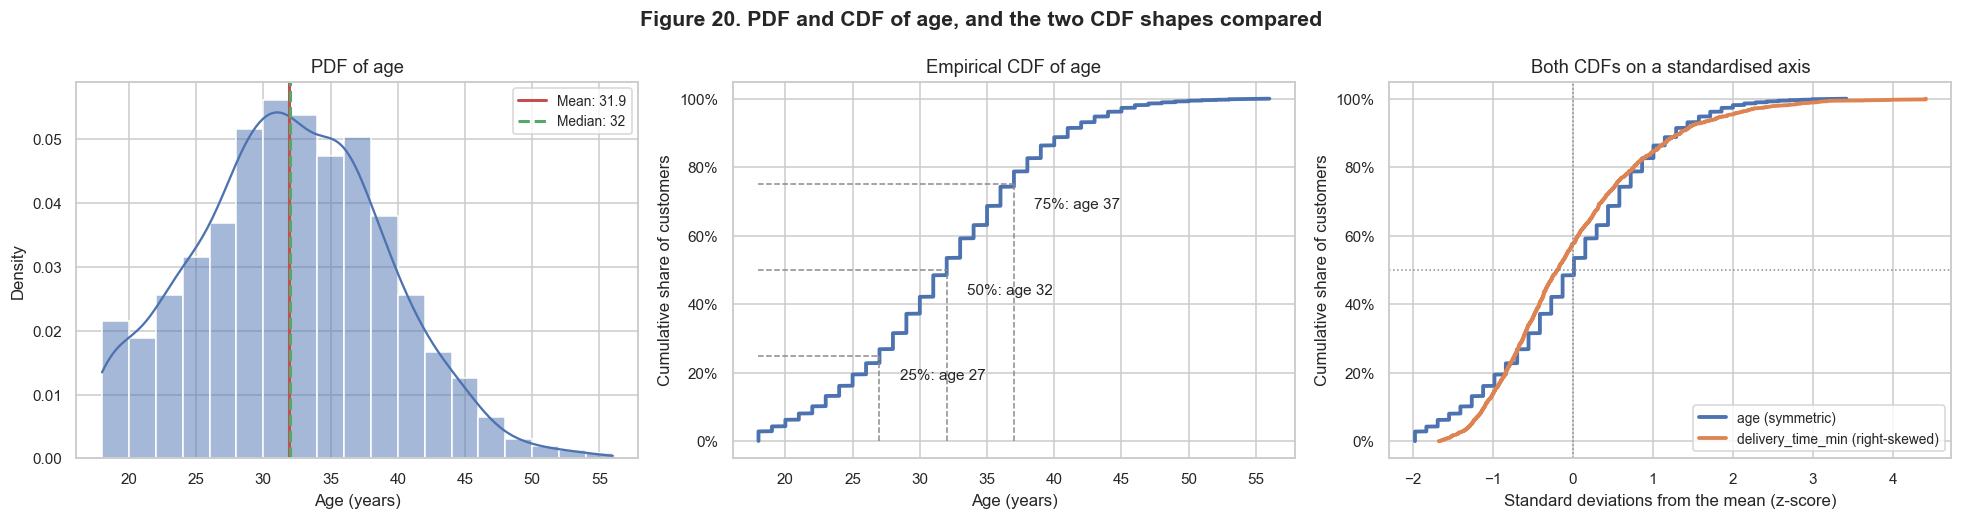

Share of customers at or below the mean -> age: 48.4%, delivery time: 57.6%
Largest z-score -> age: 3.4, delivery time: 4.4


In [46]:
age_obs = df_pre_impute["age"].dropna()
x_age, y_age = ecdf(age_obs)

# Figure 20: PDF and CDF of age, plus both CDFs on a standardised axis
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

sns.histplot(age_obs, stat="density", binwidth=2, kde=True, color=BLUE, edgecolor="white", alpha=0.5, ax=axes[0])
axes[0].axvline(age_obs.mean(), color=RED, lw=2, label=f"Mean: {age_obs.mean():.1f}")
axes[0].axvline(age_obs.median(), color=GREEN, lw=2, ls="--", label=f"Median: {age_obs.median():.0f}")
axes[0].set_title("PDF of age")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Density")
axes[0].legend()

axes[1].plot(x_age, y_age, color=BLUE, lw=2.5)
for q in [0.25, 0.5, 0.75]:
    v = np.percentile(age_obs, q * 100)
    axes[1].plot([v, v], [0, q], color=GREY, ls="--", lw=1)
    axes[1].plot([x_age.min(), v], [q, q], color=GREY, ls="--", lw=1)
    axes[1].annotate(f"{q:.0%}: age {v:.0f}", xy=(v, q), xytext=(v + 1.5, q - 0.07), fontsize=10)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set_title("Empirical CDF of age")
axes[1].set_xlabel("Age (years)")
axes[1].set_ylabel("Cumulative share of customers")

# Standardise both variables so only the shapes differ
for values, label, colour in [(age_obs, "age (symmetric)", BLUE), (observed_delivery, "delivery_time_min (right-skewed)", ORANGE)]:
    xs, ys = ecdf((values - values.mean()) / values.std())
    axes[2].plot(xs, ys, lw=2.5, color=colour, label=label)
axes[2].axvline(0, color=GREY, ls=":", lw=1)
axes[2].axhline(0.5, color=GREY, ls=":", lw=1)
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[2].set_title("Both CDFs on a standardised axis")
axes[2].set_xlabel("Standard deviations from the mean (z-score)")
axes[2].set_ylabel("Cumulative share of customers")
axes[2].legend(loc="lower right")

fig.suptitle("Figure 20. PDF and CDF of age, and the two CDF shapes compared")
plt.tight_layout()
plt.show()

print(f"Share of customers at or below the mean -> age: {(age_obs <= age_obs.mean()).mean():.1%}, "
      f"delivery time: {(observed_delivery <= observed_delivery.mean()).mean():.1%}")
print(f"Largest z-score -> age: {((age_obs - age_obs.mean()) / age_obs.std()).max():.1f}, "
      f"delivery time: {((observed_delivery - observed_delivery.mean()) / observed_delivery.std()).max():.1f}")

### Findings from the PDF and CDF

**Answers read from the delivery time CDF**

| Question | Answer |
|---|---|
| Probability that a customer's average delivery time is 30 minutes or less | 41.5% |
| Probability that a customer's average delivery time is more than 45 minutes | 16.5%, about one customer in six |
| Median | 32.25 minutes |
| 95th percentile | 56.0 minutes |

The brief words these as the probability that "a delivery" takes a given time. The column holds one average per customer, so the precise statement is about customers: 16.5% of customers average more than 45 minutes. A customer with a 40-minute average will still have some deliveries over 45, so the share of individual late deliveries is unknown and is probably different.

Including the 80 imputed values changes the answers slightly (39.9%, 15.8%, 32.25 and 55.4). The imputed values all sit at 32.25 minutes, so they count as "over 30" and "under 45" and pull both probabilities down. The four capped extreme values do not affect any of this: capped or not, they are above 45 minutes.

The risk is uneven across tiers. About 22% of customers in tier 2 and tier 3 cities average more than 45 minutes, against about 12% in tier 1 cities.

**How the two CDF shapes compare**

- The age CDF is a symmetric S. It rises slowly, climbs steeply through the middle around age 32, and flattens at the same rate on the way out. 25% of customers are 27 or younger, 50% are 32 or younger and 75% are 37 or younger, so the quartiles are evenly spaced, five years either side of the median. That even spacing is what a normal distribution looks like in a CDF.
- The delivery time CDF rises quickly at first and then bends into a long, slow approach to 100%. Getting from the 5th percentile to the median takes about 12 minutes, but getting from the median to the 95th percentile takes about 24. That lopsidedness is the right skew.
- On the standardised axis the difference is easy to see. The age curve passes close to the centre (48% of customers are at or below the mean) and ends 3.4 standard deviations out. The delivery curve is already at 58% at its mean, because most customers are faster than the average, and its tail runs out to 4.4 standard deviations.

**In plain language.** The PDF answers "which values are common?" and the CDF answers "what share of customers is at or below this value?". For a business question like "how many customers average more than 45 minutes?", the CDF gives the answer directly: read off the share at 45 minutes and subtract it from 100%.

## Which chart for which question

The charts in this notebook were chosen by the question being asked.

| Question | Chart used | Figures | Why this chart |
|---|---|---|---|
| Where are the gaps in the table? | Heatmap of `df.isna()` | 1 | Shows every cell at once, so blocks or patterns of missing data stand out |
| Are there extreme values? How do groups compare? | Box plot | 2, 3, 12, 15 | Shows the median, the quartiles and the points beyond the whiskers in one mark |
| What shape does one numeric variable have? | Histogram with KDE curve | 6, 7, 8, 18 | The bars show the counts and the curve shows the overall shape and skew |
| Did a change alter a distribution? | Overlaid KDE curves | 5 | Two smooth curves on one axis are easy to compare |
| How do two numeric variables relate? | Scatter plot | 10, 13 | Every customer is a point, so the direction, the strength and odd clusters are all visible |
| Which of many pairs are related? | Annotated correlation heatmap | 9 | Colour finds the strong pairs fast and the numbers give the exact value |
| How does something change across months? | Line plot | 11 | The line follows the order of the months |
| How does one number differ across a few categories? | Bar chart | 4, 14 | Bar length is the easiest thing to compare |
| How concentrated is revenue? | Pareto chart and cumulative curve | 16, 17 | Bars rank the groups and the line adds them up |
| What share of customers is at or below a value? | Empirical CDF | 19, 20 | Probabilities can be read straight off the curve |

## Save the cleaned dataset

The cleaned file keeps the original 18 columns plus two audit flags:

- `delivery_extreme`: True for the four customers whose delivery time was capped.
- `rating_missing`: True for the 258 customers whose rating was imputed.

The encoded columns from Task 5 are left out. They are derived features that can be rebuilt by running the Task 5 cell again, and the readable categories are more useful in a shared file.

In [47]:
# Final checks before saving
assert df.isna().sum().sum() == 0, "There are still missing values"
assert len(df) == len(df_raw), "Rows were lost during cleaning"
assert df["age"].between(18, 100).all(), "Impossible ages remain"

df.to_csv("quickbite_clean.csv", index=False)

# Read it back to confirm the file is usable
check = pd.read_csv("quickbite_clean.csv", parse_dates=["signup_date"])
print(f"Saved quickbite_clean.csv: {check.shape[0]:,} rows x {check.shape[1]} columns, "
      f"{int(check.isna().sum().sum())} missing values")

# Summary of every change made to the raw data
raw_missing = df_raw.isna().sum()
bad_age_values = ", ".join(str(int(a)) for a in sorted(df_raw.loc[bad_age, "age"]))
cleaning_log = pd.DataFrame([
    ["age", f"{int(bad_age.sum())} impossible values ({bad_age_values})", f"Set to missing, then filled with the median ({age_median:g})"],
    ["age", f"{raw_missing['age']} missing", f"Filled with the median ({age_median:g})"],
    ["delivery_time_min", f"{int(extreme_delivery.sum())} extreme values (275 to 500 min)", f"Capped at {delivery_cap:g} and flagged in delivery_extreme"],
    ["delivery_time_min", f"{raw_missing['delivery_time_min']} missing", f"Filled with the median ({del_median:g})"],
    ["avg_order_value", f"{int(bad_aov.sum())} erroneous values (18,000 to 32,000)", "Set to missing, then filled with the city-tier median"],
    ["avg_order_value", f"{raw_missing['avg_order_value']} missing", "Filled with the city-tier median"],
    ["customer_rating", f"{raw_missing['customer_rating']} missing", f"Filled with the median ({rating_median:g}) and flagged in rating_missing"],
    ["discount_used_pct", f"{raw_missing['discount_used_pct']} missing", f"Filled with the median ({disc_median:g})"],
    ["gender", f"{raw_missing['gender']} missing", "New category 'Unknown'"],
], columns=["column", "issue", "treatment"])
pd.set_option("display.max_colwidth", 80)
cleaning_log

Saved quickbite_clean.csv: 2,000 rows x 20 columns, 0 missing values


,column,issue,treatment
0,age,"3 impossible values (0, 5, 150)","Set to missing, then filled with the median (32)"
1,age,139 missing,Filled with the median (32)
2,delivery_time_min,4 extreme values (275 to 500 min),Capped at 83.9 and flagged in delivery_extreme
3,delivery_time_min,80 missing,Filled with the median (32.25)
4,avg_order_value,"4 erroneous values (18,000 to 32,000)","Set to missing, then filled with the city-tier median"
5,avg_order_value,108 missing,Filled with the city-tier median
6,customer_rating,258 missing,Filled with the median (4.4) and flagged in rating_missing
7,discount_used_pct,104 missing,Filled with the median (22.4)
8,gender,106 missing,New category 'Unknown'


## Summary of findings for the Head of Growth

**What was done.** The customer extract of 2,000 customers was checked, cleaned and analysed to find out what goes with higher annual spend. The cleaned file is saved as `quickbite_clean.csv`.

### Five things the data shows

**1. The data is usable once a small number of problems are fixed.**
About 2% of all values were missing, spread over a third of customers. Seven values were plainly wrong (three impossible ages and four order values in the tens of thousands of rupees), and four average delivery times of more than four and a half hours are suspect. The seven were blanked and refilled along with the other gaps, and the four were capped and flagged. No customers were deleted, and every change is logged in the notebook.

**2. Revenue depends on a small group, and most of all on a very small one.**
The top 20% of customers bring in 61% of revenue. That is strong concentration, though short of the textbook 80/20. Half of all revenue comes from just 12% of customers, and the top 20 individual accounts make up almost 18%. The bottom half of the customer base contributes about 16%.

**3. Spend comes from how often people order and how much they order, and frequency matters more.**
Order frequency has the strongest link with annual spend, and basket size comes second. The top 20% order more than twice as often as everyone else (a median of 46 orders a year against 20), and their baskets are about 70% larger (492 rupees against 287). Customers who open the app most also spend more. City tier, age, tenure and discount level make almost no difference.

**4. The "average customer" figure is misleading.**
Average annual spend is about 13,000 rupees, but the typical customer spends about 7,100. Three in four customers spend less than the average. Plans built on the average will overstate what an ordinary customer is worth.

**5. One customer in six averages more than 45 minutes per delivery, and ratings are missing where delivery is slow.**
The typical customer's average delivery time is 32 minutes, and nine in ten customers average under 50 minutes. About 16% average more than 45 minutes, rising to more than one in five outside the metros. Customers whose deliveries average more than 35 minutes are almost six times as likely to have no rating on file (about 26% against 4%). The 4.3 average rating therefore says little about the customers with the slowest service.

### Two recommendations

**1. Manage the heavy users as a named group.**
Identify the roughly 240 customers who generate half of revenue, give them an owner in the team, and watch their ordering for early signs of a drop. Membership tier alone will not find them: 45% of the top 20% are on Basic.

**2. Set a delivery-time target for tier 2 and tier 3 cities, and ask for a rating after every slow delivery.**
A target such as "90% of customers averaging under 45 minutes", tracked by city, would show whether the gap to the metros is closing. Asking for a rating after slow deliveries would fill the blind spot described in point 5.

### Limits of this analysis

- The file is a single snapshot of established customers, pulled on 31 October 2026. Everyone in it has at least 12 months of tenure and ordered at least 5 times in the past year, so it says nothing about new-customer acquisition or about customers who left.
- The analysis is descriptive. It shows what moves together, not what causes what. Whether raising order frequency or speeding up delivery would raise spend needs a controlled test.
- Delivery times are averages per customer. The share of individual orders that arrive late is not in this file.
- Three items should be confirmed with the data team: the largest account (3.3% of revenue, and the conclusions hold without it), the four customers flagged with average delivery times of more than four and a half hours, and the order count, which is bucketed and stops at exactly 400.